---
title: "Sit and Grace (1981): bubble interaction and interphase mass transfer"
description: "Sit and Grace postulate that bubble interaction raises only the throughflow term of the single-bubble interphase coefficient and derive their freely-bubbling eqns (3), (4) from it; the page tests whether the paper's own printed numbers decide that, with one small pymrm solve for the penetration term and pymrm checks on the tracer balance."
categories: [sec:E, struct:S1, struct:S4, tier:T1, data:tier2, phase:gas-solid]
date: 2026-11-27
---

# Sit and Grace (1981): bubble interaction and interphase mass transfer

**Catalog ID:** `E1.4` · **Structures:** `S1` (tracer balance of a growing bubble),
`S4` (the penetration problem behind the diffusive term) · **Tier:** T1

Sit and Grace measured ozone leaving pairs of interacting bubbles in a two-dimensional
bed of 390 μm glass beads and found the front bubble of a pair transferring two to three
times faster than an isolated bubble. They split the single-bubble coefficient into a
throughflow term and a penetration (diffusion) term, eqns (1) and (2), and postulate that
interaction raises only the throughflow term; a factor on that term and a coalescing
fraction then give eqns (3) and (4) for freely bubbling beds. The paper itself calls its
explanation "semi-quantitative" (p. 333). This page tests the postulate, it does not
endorse it: do the paper's printed numbers (Table 2, the 390 μm coefficients of p. 330,
Table 1's tracer accounting) decide that the enhancement sits in the throughflow term
with the diffusive term unaltered, and do eqns (3), (4) follow from them?

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.6"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "E1.4-sit-grace-interphase-mass-transfer"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes one small solve (the penetration problem with
# construct_grad, construct_div and compute_boundary_values) and the checks (find_roots and
# observed_orders on the plain numpy tracer march); model.py is put on sys.path by setup().
import math
import re
from dataclasses import dataclass, field, replace
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_claims, load_data, load_meta
from model import (THROUGHFLOW, Penetration, bubble_velocity, equivalent_diameter, int_kd_s_over_v,
                   int_s_over_v, k_diffusion, k_throughflow, renewal_factor, tracer_march)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
E12 = "E1.2-davidson-bubble"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In a bubbling fluidized bed, gas leaves a bubble for the dense phase in two ways: it
flows through the bubble (the throughflow, which in Davidson's picture enters at the
base and leaves at the roof, page [`E1.2`](../E1.2-davidson-bubble/)), and it diffuses
into the emulsion that slides past the bubble surface (a penetration process, exposure
time about the bubble's own passage time). Reactor models such as
[`E2.1`](../E2.1-kunii-levenspiel-bubbling-bed/) add the two as a sum of coefficients.

Sit and Grace (1981) followed pairs of bubbles injected one after the other into a
two-dimensional column (0.56 m wide, 9 mm thick) of 390 μm glass beads, with ozone as the
tracer, and measured the concentration in each bubble over time (their Figs. 8 to 10 and
Table 1). During the approach period the front bubble of a vertical pair transfers at
"9.6 and 8.5 cm/s for the front bubble in vertical and oblique alignment respectively"
against 3.4 cm/s for an isolated bubble (p. 330). Their Table 2 collects five studies whose
enhancement grows with particle size, and they reason from it:

> "These considerations lead us to a postulate which explains in a semi-quantitative manner
> the results summarized in Table 2. We postulate that bubble interaction leads to an
> increase in the throughflow component of transfer, while the diffusion component is not
> appreciably altered." (p. 333)

Then, for freely bubbling beds (p. 334): "A conservative estimate for the overall enhancement
factor (based on 40% of bubbles coalescing at any instant) is therefore (1.8 × 0.4 + 0.6) =
1.32", which turns the throughflow constants $1/\pi$ and $1/4$ into 0.4 and 1/3, "given only to
a single significant figure".

The paper prints three independent pieces of evidence that bear on the postulate: Table 2,
the 390 μm coefficients, and Table 1. None of the fits behind 9.6, 8.5, 3.4 or 1.8 is
printed (they are in a thesis, reference [14], and a paper of the same group, [5]); the page does not
redo them and does not put an error on them beyond arithmetic. Also not covered: bubble
growth (Figs. 5 to 7, page `E1.3`), the 30 to 60 % visual estimate itself, heat transfer
beyond the dimensional check of the p. 334 analogy, and the cloud around a 390 μm bubble.

## The published model

Eqns (1) and (2) (p. 333, "given [5]"), with the first term "from Murray's hydrodynamic
analysis" and the second "derived from the penetration theory":

$$K_{GT} = \frac{U_{mf}}{\pi} + \left(\frac{4\mathcal{D}_G\,\epsilon_{mf}\,U_B}{\pi D_B}\right)^{1/2}
\quad\text{(1, circular 2-D bubble)},\qquad
K_{GT} = \frac{U_{mf}}{4} + \left(\frac{4\mathcal{D}_G\,\epsilon_{mf}\,U_B}{\pi D_B}\right)^{1/2}
\quad\text{(2, sphere)}.$$

Eqns (3) and (4) (p. 334), freely bubbling beds, with mean bubble size and velocity:

$$\bar K_{GT} = 0.4\,U_{mf} + \left(\frac{4\mathcal{D}_G\,\epsilon_{mf}\,\bar U_B}{\pi \bar D_B}\right)^{1/2}
\quad\text{(3, 2-D)},\qquad
\bar K_{GT} = \frac{U_{mf}}{3} + \left(\frac{4\mathcal{D}_G\,\epsilon_{mf}\,\bar U_B}{\pi \bar D_B}\right)^{1/2}
\quad\text{(4, 3-D)}.$$

The step between them (p. 334): an enhancement $E_T$ = 1.8 on the throughflow term for a
pair "in the final 0.8 s of the coalescence process (Table 2)" (Table 1 spans 0.3 to 1.1 s,
so this is Table 1), applied to a coalescing fraction $f_c$ = 0.4:

$$E = E_T f_c + (1 - f_c) = 1.32,\qquad \text{constants } E/\pi \text{ (2-D) and } E/4 \text{ (3-D)}. \tag{E5}$$

Forms the page adds (the paper does not print them):

- **Throughflow** $k_T = q/S_b$. Murray's $q$ (cited, not read) is inferred from (1), (2):
  $2U_{mf}R$ per unit depth and $\pi R^2 U_{mf}$. Davidson's (page `E1.2`) is $4U_{mf}R$
  and $3\pi R^2 U_{mf}$, so $2U_{mf}/\pi$ and $3U_{mf}/4$.
- **Penetration** (S4). An emulsion element exposed for $t_e = D_B/U_B$:
  $\epsilon_{mf}\,\partial c/\partial t = \mathcal{D}_G\,\partial^2 c/\partial x^2$, $c(0,t) = C_b$,
  $c(x,0) = 0$. In $x^{\ast} = x(\epsilon_{mf}/(\mathcal{D}_G t_e))^{1/2}$, $t^{\ast} = t/t_e$ it is
  $c_t = c_{xx}$, and the absorbed amount $M^{\ast} = \int_0^1 N^{\ast}\,dt^{\ast} = 2/\sqrt{\pi}$ gives
  $k_D = M^{\ast}(\epsilon_{mf}\mathcal{D}_G/t_e)^{1/2}$, the second term of (1). The
  $\epsilon_{mf}^{1/2}$ means capacity $\epsilon_{mf}$ with diffusivity $\mathcal{D}_G$ (no
  porosity on the diffusivity).
- **Surface renewal in potential flow** (E8): local flux
  $C_b(\mathcal{D}/\pi)^{1/2}u_s r^j/(\int_0^\theta u_s r^{2j}R\,d\theta')^{1/2}$ with
  $u_s = 2U\sin\theta$, $j = 0$ (circle) or $u_s = 1.5U\sin\theta$, $r = R\sin\theta$,
  $j = 1$ (sphere). Its surface mean is exactly the printed term for a sphere and
  $2\sqrt2/\pi$ of it for a circle.
- **Tracer balance of a growing 2-D bubble** (S1, E9):
  $d(V_BC_B)/dt = -K S_B C_B$ with the dense phase at zero tracer, $V_B = wA$,
  $S_B = \phi\,w\,\pi D_{eq}$, $D_{eq} = (4A/\pi)^{1/2}$, $w$ the bubble thickness, $\phi$ a
  perimeter factor. The paper's definition is "the same as that described by Chavarie and
  Grace [4]" and not printed; this is the page's reading.
- **Table 2 as a coefficient ratio** (E10): "Overall % Inc. over Single Bubble" read as
  $K_{int}/K_{single} - 1 = (E_T - 1) f_T + (E_D - 1)(1 - f_T)$ with $f_T = k_T/(k_T + k_D)$.
  The paper does not define the column; this is the only reading under which eqns (1) to (4)
  predict it.

| symbol | meaning | code |
| --- | --- | --- |
| $U_{mf}$ | minimum fluidization velocity, cm/s | `umf` |
| $\mathcal{D}_G$ | molecular diffusivity of the tracer, cm²/s | `DG` |
| $\epsilon_{mf}$ | voidage at minimum fluidization (not printed) | `eps` |
| $U_B$, $D_B$ | bubble velocity (not printed) and diameter | `UB`, `DB` |
| $k_T$, $k_D$ | throughflow and penetration terms | `k_throughflow`, `k_diffusion` |
| $f_T$ | throughflow fraction of the single-bubble coefficient | `fT` |
| $E_T$, $E_D$ | enhancement of each term | `ET`, `ED` |
| $V_B$, $C_B$, $w$ | bubble volume, tracer concentration, thickness | `V`, `C`, `w` |

## Parameters and assumptions

Every input the paper does not print is a named page input, and every statement about
Table 2 or about eqn (1) at the paper's conditions is evaluated at every corner of these
brackets (rule: a statement over a range holds at every point it covers); nothing is fitted
to make the postulate hold.

- $\epsilon_{mf}$: 0.38 to 0.50 for every particle, independently per Table 2 row.
- $U_B$ of the Table 2 rows: $c\,(gD_B)^{1/2}$ with $c$ 0.5 to 0.8, independently per row,
  over the printed $D_B$ range of the row.
- $U_B$ of the 390 μm bubbles: the slope of the front bubble's nose height in the approach
  period, read from Fig. 4 (the paper points to Fig. 4 for its "relatively constant"
  velocity, p. 330). Fig. 4 is an oblique pair; it is the only velocity record printed.
- The test condition **T** of the check values (U_mf 11.2 cm/s, D_G 0.2 cm²/s, D_B 15 cm,
  eps 0.40, U_B 90 cm/s) is a test point for the functions, not a statement about the
  paper; likewise the Table 2 midpoint condition **T2** (eps 0.40, c 0.711).

In [3]:
EPS_BR = (0.38, 0.50)        # voidage at minimum fluidization, page bracket (not printed)
C_BR = (0.5, 0.8)            # U_B = c (g D_B)^(1/2), page bracket for the Table 2 rows
G = 981.0                    # cm/s2
T = dict(umf=11.2, DG=0.2, DB=15.0, eps=0.40, UB=90.0, w=0.9)   # check-value test condition
T2 = dict(eps=0.40, c=0.711)  # Table 2 check-value condition, D_B at the midpoint of the row
N_SPACE = (25, 50, 100, 200, 400)    # penetration: cells on 0 < x < 12, exact time
N_BE_CELLS, NT_BE = 800, (50, 100, 200, 400, 800)   # penetration: backward Euler ladder
S1_LADDER = tuple(20 * 2 ** k for k in range(6))     # tracer march: steps over 0.3 to 0.6 s
F9_ERR = 0.015               # Fig. 9 reading error, vol % (sidecar)
CONF = (0.90, 0.95)          # the confidence levels of the p. 330 verdict

## The data

Five files, all read from 300 dpi renders of the scan (its text layer drops every equation
and garbles table cells; each file has a `.meta.yaml` sidecar):

| file | what it is |
| --- | --- |
| `sit-grace-1981-printed-numbers.csv` | every number of the text and equations the page uses, as printed (strings) |
| `sit-grace-1981-table1.csv` | Table 1, the tracer accounting of a vertical pair, every cell as printed |
| `sit-grace-1981-table2.csv` | Table 2, the five studies, every cell as printed ("12-15", "3-8", "small") |
| `sit-grace-1981-fig4.csv` | Fig. 4, nose height of the front bubble in the approach period (the slope fit uses the markers counted in the data summary below) |
| `sit-grace-1981-fig9.csv` | Fig. 9, concentration of the front, back and single bubble at the Table 1 times |

The page loads one claim from page `E1.2` (its through-flow coefficient of the
two-dimensional bubble, $8/\pi$ in $u_{mf}/d_b$ as $q/(\pi R^2)$, from its pymrm solve) and
cites that page's reproduction of the three-dimensional 4.5 of Kunii and Levenspiel; it
loads no other page's dataset. Findings in the printed data that matter below: two
$V_BC_B$ cells of Table 1 disagree with $V_B \times C_B$; Pereira's row is "3-8" in Table 2
and "5-8%" in the text (p. 332); the "small" of the 90 μm row is described as "less than for
the larger particles used in the present work" (p. 333); no row prints $\epsilon_{mf}$ or $U_B$.

In [4]:
pn = load_data("sit-grace-1981-printed-numbers.csv", page=PAGE, dtype=str)
t1 = load_data("sit-grace-1981-table1.csv", page=PAGE, dtype=str, keep_default_na=False)
t2 = load_data("sit-grace-1981-table2.csv", page=PAGE, dtype=str, keep_default_na=False)
f4 = load_data("sit-grace-1981-fig4.csv", page=PAGE)
f9 = load_data("sit-grace-1981-fig9.csv", page=PAGE)
PN = dict(zip(pn.name, pn.printed))
print(cite_data(load_meta("sit-grace-1981-table1.csv", page=PAGE)))
print(f"\nprinted numbers: {len(pn)}; Table 1: {len(t1)} rows; Table 2: {len(t2)} rows; "
      f"Fig. 4: {len(f4)} markers ({int(f4.in_fit.sum())} in the slope); Fig. 9: {len(f9)} reads\n")
print(t1[["time_s", "bubble", "V_B_cm3", "C_B_vol_pct", "VBCB_cm3", "cum_transfer_cm3",
          "cum_transfer_pct", "elapsed_pct"]].to_string(index=False))
print()
print(t2.drop(columns=["ref"]).to_string(index=False))
E12_CLAIMS = load_claims(E12)
print(f"\nE1.2 (loaded claims): 2-D through-flow q/(pi R^2) = "
      f"{E12_CLAIMS['throughflow_2d_coefficient']:.7f} u_mf/d_b from its solve; its 3-D "
      f"coefficient reproduces Kunii and Levenspiel's 4.5 to {E12_CLAIMS['throughflow_coefficient_rel']:.1e}")

Sit, S. P.; Grace, J. R. (1981) — Chemical Engineering Science 36, 327-335 — doi:10.1016/0009-2509(81)85012-9 — table

printed numbers: 32; Table 1: 10 rows; Table 2: 5 rows; Fig. 4: 10 markers (8 in the slope); Fig. 9: 14 reads

time_s    bubble V_B_cm3 C_B_vol_pct VBCB_cm3 cum_transfer_cm3 cum_transfer_pct elapsed_pct
   0.3     front     160        1.52     2.44                                              
   0.3      rear     130        1.90     2.46                0                0           0
   0.3       sum     290                 4.90                                              
   0.6     front     280        0.40     1.12                                              
   0.6      rear     340        0.64     2.34             1.44               46          38
   0.6       sum     620                 3.46                                              
   0.7     front     250        0.38     0.96                                              
   0.7      rear     343        0.

## PyMRM implementation

**The penetration problem (S4).** `model.Penetration` discretises $c_t = c_{xx}$ on
$0 < x < L$, $L$ = 12 (where $\mathrm{erfc}(L/2)$ = 2e-17), with finite volumes on a uniform
grid of shape `(n, 1)`: `construct_grad` with two Dirichlet dictionaries and
`construct_div` with `nu = 0` (Cartesian), assembled once, give $dc/dt = Ac + b$. The
dictionaries use the outward normal, $a\,\partial c/\partial n + b\,c = d$:

```python
bc = ({"a": 0, "b": 1, "d": 1},   # x = 0: c = 1 (the bubble gas)
      {"a": 0, "b": 1, "d": 0})   # x = L: c = 0 (fresh emulsion)
```

Time is exact: the matrix exponential of the augmented constant operator acting on
$(c, Q_{in}, Q_{out}, 1)$, where $Q_{in}$, $Q_{out}$ accumulate the face fluxes, so the space
error is measured alone. The absorbed amount is read twice, as the sum of exact cell
volumes times $c$ and as $Q_{in} - Q_{out}$; the two agree by the discrete conservation of
the scheme (an identity, not a second route). The face flux at $t = 1$ is read with
`compute_boundary_values` under the same dictionaries. A backward Euler ladder (one sparse
LU per level) measures the time error alone on 800 cells.

**The tracer balance (S1).** `model.tracer_march` integrates $d(V_BC_B)/dt = -K S_B C_B$ for
$y = V_BC_B$ implicitly, with $V_B$ linear in time between the Table 1 volumes, and
`pymrm.checks.find_roots` inverts it for the $K$ that reproduces a Table 1 cell, raising
unless there is exactly one root in 0.5 to 100 cm/s. `pymrm.checks.observed_orders` gives the
orders and the Richardson estimate of every ladder. Every quantity also has a closed form
(the Higbie integral, power-law integrals in $V$); those are the second routes and the
check values.

One study function computes every number the page states from one configuration; the
break table at the end reruns it with one defect at a time.

In [5]:
@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: dict = field(default_factory=lambda: dict(PN))   # printed numbers (strings)
    t1: pd.DataFrame = field(default_factory=lambda: t1.copy())
    t2: pd.DataFrame = field(default_factory=lambda: t2.copy())
    f4: pd.DataFrame = field(default_factory=lambda: f4.copy())
    f9: pd.DataFrame = field(default_factory=lambda: f9.copy())
    table: dict = field(default_factory=lambda: THROUGHFLOW)   # q/S_b coefficients
    convention: str = "capacity"     # eps_mf inside the root (capacity eps, diffusivity D_G)
    size_factor: float = 1.0         # multiplies D_B in the penetration term
    enhance_on: str = "throughflow"  # the term an enhancement factor multiplies
    dim_2d: int = 2                  # eqn (1) for 2-d columns
    dim_3d: int = 3                  # eqn (2) for 3-d columns
    w_cm: float = None               # bubble thickness; None: the printed 9 mm
    complement: str = "1-fc"         # E5: E_T f_c + (1 - f_c)
    c11: str = "printed"             # Table 1 accounting at 1.1 s from the printed V_B C_B
    hold_volume: bool = False        # E9 with V_B held at its 0.3 s value
    L: float = 12.0                  # penetration domain
    d_left: float = 1.0              # datum of the left Dirichlet dictionary
    first_cell: float = 0.0          # initial value of the first cell
    theta: float = 1.0               # time scheme of both ladders (1: backward Euler)
    dilution: bool = True            # march V_B C_B (True) or C_B alone
    comp_scale: float = 1.0          # boundary factor of the S4 round-off companions
    comp_s1: float = 1.0             # y0 factor of the S1 round-off companion
    renewal_circle: float = 2.0      # surface velocity coefficient, circle
    renewal_sphere: float = 1.5      # surface velocity coefficient, sphere
    quantile: str = "two-sided"      # normal test behind the 90 %/95 % verdict
    hu_product: bool = True          # the product's own half unit in a Table 1 allowance
    f9_err: float = F9_ERR           # Fig. 9 reading error, vol %
    fit_q: str = "t"                 # quantile of the free fit's intervals (t with n - 2 dof)


C0 = Cfg()


def num(C, name):
    """A printed number as a float."""
    return float(C.pn[name])


def rng(s):
    """A printed range "12-15" (or a single value) as (low, high)."""
    a, _, b = str(s).partition("-")
    return float(a), float(b or a)


def thickness(C):
    return num(C, "column_thickness") / 10.0 if C.w_cm is None else C.w_cm


def cell(C, time, bubble, col):
    """One Table 1 cell, as printed (string)."""
    sel = C.t1.bubble == bubble
    if bubble != "resultant":                 # the one resultant row is found by its label
        sel &= C.t1.time_s == time
    return C.t1[sel][col].iloc[0]


def unit(s):
    """The unit of the last printed digit of a numeric string."""
    s = str(s).strip()
    return 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)


def kT(C, umf, dim, rule="murray"):
    return k_throughflow(umf, dim, rule, C.table)


def kD(C, DG, eps, UB, DB):
    return k_diffusion(DG, eps, UB, DB, C.convention, C.size_factor)


def pct_from_E(E, fT, on):
    """Fractional increase of the coefficient for an enhancement E on one term."""
    fT = np.asarray(fT, dtype=float)
    return (E - 1.0) * {"throughflow": fT, "diffusion": 1.0 - fT, "whole": np.ones_like(fT)}[on]


def E_from_pct(p, fT, on):
    fT = np.asarray(fT, dtype=float)
    return 1.0 + p / {"throughflow": fT, "diffusion": 1.0 - fT, "whole": np.ones_like(fT)}[on]


def overall_E(C, fc):
    """E5: the enhancement of the throughflow term in a bed with coalescing fraction fc."""
    rest = 1.0 - fc if C.complement == "1-fc" else fc
    return num(C, "enh_throughflow") * fc + rest

In [6]:
def t2_rows(C):
    """Table 2 rows as numbers; column 2-d or 3-d mapped to the equation the study uses."""
    rows = []
    for _, r in C.t2.iterrows():
        lo, hi = rng(r.DB_cm)
        dim = C.dim_2d if r.column == "2-d" else C.dim_3d
        pct = None if r.overall_pct_inc == "small" else rng(r.overall_pct_inc)
        rows.append(dict(key=KEYS[r.dp_um], umf=float(r.umf_cm_s), DG=float(r.DG_cm2_s),
                         DB=(lo, hi), dim=dim, pct=pct))
    return {r["key"]: r for r in rows}


KEYS = {"390": "p390", "320": "t320", "160": "t160", "93": "per", "90": "sg90"}


def decidable_pairs(R):
    """(higher, lower) pairs whose printed increases differ beyond their half units, plus the
    text's "less than for the larger particles used in the present work" for the 90 um row."""
    num_rows = [k for k in ORDER if R[k]["pct"] is not None]
    out = [(h, l) for h in num_rows for l in num_rows
           if R[h]["pct"][0] - 0.5 > R[l]["pct"][1] + 0.5]
    return out + [("p390", "sg90")]


def fT_row(C, r, eps, c, DB):
    """Throughflow fraction of a Table 2 row (arrays broadcast)."""
    k_t = kT(C, r["umf"], r["dim"])
    k_d = kD(C, r["DG"], eps, bubble_velocity(DB, c, G), DB)
    return k_t / (k_t + k_d)


def corners(r):
    """Every corner of a row's brackets: eps, c and its printed D_B ends."""
    dbs = sorted(set(r["DB"]))
    return np.array(list(product(EPS_BR, C_BR, dbs)))


def fT_corners(C, r):
    e, c, d = corners(r).T
    return fT_row(C, r, e, c, d)

In [7]:
S4_CACHE = {}


def s4_study(C):
    """V1: the penetration problem, space ladder in exact time and backward Euler ladder."""
    key = (C.L, C.d_left, C.first_cell, C.theta, C.comp_scale)
    if key not in S4_CACHE:
        S4_CACHE[key] = _s4(C)
    return S4_CACHE[key]


def _s4(C):
    ex_a, ex_f = 2.0 / math.sqrt(math.pi), 1.0 / math.sqrt(math.pi)
    P = {n: Penetration(n, C.L, C.d_left, C.first_cell) for n in N_SPACE}
    S = {n: P[n].exact_time() for n in N_SPACE}
    ra = observed_orders(lambda n: S[n]["amount"], N_SPACE)
    rf = observed_orders(lambda n: S[n]["flux"], N_SPACE)
    nf = N_SPACE[-1]
    comp = P[nf].exact_time(method="expm_multiply", bc_scale=C.comp_scale)["amount"]
    M = {"s4_amount_order_min": min(ra["orders"]), "s4_amount_order_max": max(ra["orders"]),
         "s4_flux_order_min": min(rf["orders"]), "s4_flux_order_max": max(rf["orders"]),
         "s4_amount_gap": abs(ra["extrapolated"] - ex_a), "s4_flux_gap": abs(rf["extrapolated"] - ex_f),
         "s4_amount_err_n100": S[100]["amount"] - ex_a,
         "s4_identity": max(abs(s["amount"] - (s["q_in"] - s["q_out"])) for s in S.values()),
         "s4_companion": abs(S[nf]["amount"] - comp) / abs(ra["values"][-1] - ra["values"][-2]),
         "_s4_amounts": ra["values"], "_s4_orders": ra["orders"], "_s4_forders": rf["orders"],
         "_s4_extrap": ra["extrapolated"], "_s4_fextrap": rf["extrapolated"]}
    pb = Penetration(N_BE_CELLS, C.L, C.d_left, C.first_cell)
    rb = observed_orders(lambda nt: pb.stepped(nt, theta=C.theta), NT_BE)
    comp_b = pb.stepped(NT_BE[-1], theta=C.theta, route="banded", bc_scale=C.comp_scale)
    M |= {"s4_be_order_min": min(rb["orders"]), "s4_be_order_max": max(rb["orders"]),
          "s4_be_gap": abs(rb["extrapolated"] - ex_a),
          "s4_be_companion": abs(rb["values"][-1] - comp_b) / abs(rb["values"][-1] - rb["values"][-2]),
          "_s4_be_orders": rb["orders"]}
    return M


def r1_terms(C):
    """R1: the two terms of eqns (1), (2), the renewal factors and the readings M8, M9."""
    t = t2_rows(C)["p390"]
    k_e12 = E12_CLAIMS["throughflow_2d_coefficient"] * t["umf"] / 4.0   # q/S_b from E1.2's solve
    sphere = renewal_factor("sphere", C.renewal_sphere)
    circle = renewal_factor("circle", C.renewal_circle)
    UB = fig4_slope(C)[0]
    e, d = np.array(list(product(EPS_BR, sorted(set(t["DB"]))))).T
    k_d = kD(C, t["DG"], e, UB, d)
    m9 = k_diffusion(t["DG"], e, UB, d, "effective", C.size_factor) / k_d
    return {"r1_md_2d": C.table["murray"][2] / C.table["davidson"][2],
            "r1_md_3d": C.table["murray"][3] / C.table["davidson"][3],
            "r1_E12_gap": abs(float(kT(C, t["umf"], 2, "davidson")) / k_e12 - 1.0),
            "r1_renewal_circle": circle, "r1_renewal_sphere_gap": abs(sphere - 1.0),
            "r1_m8_min": float(((1 - circle) * k_d).min()), "r1_m8_max": float(((1 - circle) * k_d).max()),
            "r1_m9_min": float(m9.min()), "r1_m9_max": float(m9.max())}


def fig4_slope(C):
    """U_B of the 390 um front bubble: least-squares slope of Fig. 4 and its standard error."""
    d = C.f4[C.f4.in_fit == 1]
    x, y = d.time_s.to_numpy(float), d.height_cm.to_numpy(float)
    b, a = np.polyfit(x, y, 1)
    r = y - (a + b * x)
    return b, math.sqrt(r @ r / (len(x) - 2) / ((x - x.mean()) @ (x - x.mean()))), len(x)


ORDER = ["p390", "t320", "t160", "per", "sg90"]


def joint(arrs):
    """Broadcast per-row corner arrays onto the grid of every joint corner."""
    n = len(arrs)
    return [a.reshape([-1 if i == j else 1 for j in range(n)]) for i, a in enumerate(arrs)]


def r2_ordering(C, F):
    """R2(a): ordering of the decidable pairs over every joint corner of the five rows."""
    J = dict(zip(ORDER, joint([F[k] for k in ORDER])))
    PAIRS = decidable_pairs(t2_rows(C))
    conc_t = sum((J[h] > J[l]).astype(int) for h, l in PAIRS)
    conc_d = sum((J[h] < J[l]).astype(int) for h, l in PAIRS)
    margin = min(float(np.min(np.abs(F[h][:, None] / F[l][None, :] - 1))) for h, l in PAIRS)
    lo3, hi3 = F["p390"].min(), F["p390"].max()
    lo2, hi2 = F["t320"].min(), F["t320"].max()
    M = {"r2_conc_T_min": int(conc_t.min()), "r2_conc_T_max": int(conc_t.max()),
         "r2_conc_D_min": int(conc_d.min()), "r2_conc_D_max": int(conc_d.max()),
         "r2_conc__margin": margin, "r2_n_pairs": len(PAIRS),
         "r2_conc_U": sum(int(pct_from_E(1.32, F[h].max(), "whole") > pct_from_E(1.32, F[l].min(), "whole"))
                          for h, l in PAIRS),   # uniform enhancement: the same increase in every row
         "r2_overlap_390_320": int(lo3 <= hi2 and lo2 <= hi3),
         "_n_joint": conc_t.size}
    for k in ORDER:
        M[f"r2_fT_{k}_min"], M[f"r2_fT_{k}_max"] = float(F[k].min()), float(F[k].max())
    return M


def r2_size(C, R, F):
    """R2(b): the E_T - 1 each numeric row implies, the 160 um row from the 390 um row, and
    the increase eqns (3), (4) and E = 1.32 predict for every row, over every corner."""
    on, M = C.enhance_on, {}
    for k in ("p390", "t320", "t160"):
        e1 = E_from_pct(R[k]["pct"][0] / 100, F[k], on) - 1
        M[f"r2_ET1_{k}_min"], M[f"r2_ET1_{k}_max"] = float(e1.min()), float(e1.max())
    lo, hi = R["per"]["pct"]
    M["r2_ET1_per_min"] = float((E_from_pct(lo / 100, F["per"], on) - 1).min())
    M["r2_ET1_per_max"] = float((E_from_pct(hi / 100, F["per"], on) - 1).max())
    M["r2_ET1_per_text_min"] = float((E_from_pct(rng(C.pn["pereira_text_pct"])[0] / 100, F["per"], on) - 1).min())
    E390 = E_from_pct(R["p390"]["pct"][0] / 100, F["p390"][:, None], on)
    pred = 100 * pct_from_E(E390, F["t160"][None, :], on)
    M["r2_pred160_min"], M["r2_pred160_max"] = float(pred.min()), float(pred.max())
    edge = R["t160"]["pct"][0] + 0.5            # the printed 15 and its half unit
    M["r2_pred160_above"] = int(np.sum(pred > edge))
    M["r2_pred160_above__margin"] = float(np.min(np.abs(pred - edge)) / edge)
    M["_n_160"] = pred.size
    E = overall_E(C, num(C, "fc_used_pct") / 100)
    for k in ORDER:
        dim = R[k]["dim"]
        Ep = num(C, "eqn3_const") * math.pi if dim == 2 else 4.0 / num(C, "eqn4_den")
        for tag, EE in (("132", E), ("pc", Ep)):
            p = 100 * pct_from_E(EE, F[k], on)
            M[f"r2_pred{tag}_{k}_min"], M[f"r2_pred{tag}_{k}_max"] = float(p.min()), float(p.max())
    for tag in ("132", "pc"):
        inside, gaps = 0, []
        for k in ("p390", "t320", "t160", "per"):
            a, b = M[f"r2_pred{tag}_{k}_min"], M[f"r2_pred{tag}_{k}_max"]
            plo, phi_ = R[k]["pct"][0] - 0.5, R[k]["pct"][1] + 0.5   # printed, with half units
            inside += int(plo <= b and a <= phi_)
            gaps.append(min(abs(plo - b), abs(a - phi_)) / (phi_ - 0.5))
        M[f"r2_inside_{tag}"], M[f"r2_inside_{tag}__margin"] = inside, min(gaps)
    return M


def fit_two_parts(F, ys, quantile="t"):
    """R2(c): least squares of y = a f + b (1 - f) per joint corner; a = E_T - 1, b = E_D - 1.

    Returns a, b, the 95 % half-widths (t quantile, n - 2 dof) and the residuals."""
    f = np.stack(np.broadcast_arrays(*joint(F)))
    y = np.asarray(ys, dtype=float).reshape([-1] + [1] * (f.ndim - 1))
    g = 1.0 - f
    Sff, Sfg, Sgg = (f * f).sum(0), (f * g).sum(0), (g * g).sum(0)
    Sfy, Sgy = (f * y).sum(0), (g * y).sum(0)
    det = Sff * Sgg - Sfg ** 2
    a = (Sgg * Sfy - Sfg * Sgy) / det
    b = (Sff * Sgy - Sfg * Sfy) / det
    res = y - a * f - b * g
    dof = len(F) - 2
    s2 = (res ** 2).sum(0) / dof
    tq = stats.t.ppf(0.975, dof) if quantile == "t" else stats.norm.ppf(0.975)
    return a, b, tq * np.sqrt(s2 * Sgg / det), tq * np.sqrt(s2 * Sff / det), res


def r2_fit(C, R, F):
    """R2(c): both parts free, with and without Pereira's row, over every corner."""
    M, keys3 = {}, ["p390", "t320", "t160"]
    per_lo, per_hi = R["per"]["pct"]
    t_lo, t_hi = rng(C.pn["pereira_text_pct"])
    variants = [(per_lo + per_hi) / 2, per_lo, per_hi, (t_lo + t_hi) / 2]
    y3 = [R[k]["pct"][0] / 100 for k in keys3]
    out = {}
    for tag, keys, ylist in (("fit4", keys3 + ["per"], [y3 + [v / 100] for v in variants]),
                             ("fit3", keys3, [y3])):
        res = [fit_two_parts([F[k] for k in keys], y, C.fit_q) for y in ylist]
        a = np.concatenate([r[0].ravel() for r in res])
        b = np.concatenate([r[1].ravel() for r in res])
        hw = np.concatenate([r[3].ravel() for r in res])
        M[f"r2_{tag}_a_min"], M[f"r2_{tag}_a_max"] = float(a.min()), float(a.max())
        M[f"r2_{tag}_b_min"], M[f"r2_{tag}_b_max"] = float(b.min()), float(b.max())
        M[f"r2_{tag}_bhw_min"], M[f"r2_{tag}_bhw_max"] = float(hw.min()), float(hw.max())
        M[f"r2_{tag}_b_ci0"] = int(np.sum(np.abs(b) < hw))
        M[f"r2_{tag}_b_ci0__margin"] = float(np.min(np.abs(np.abs(b) - hw) / hw))
        M[f"_n_{tag}"] = a.size
        M[f"r2_{tag}_n"] = a.size
        out[tag] = res
    r160 = np.concatenate([100 * r[4][2].ravel() for r in out["fit4"]])
    M["r2_fit4_res160_min"], M["r2_fit4_res160_max"] = float(r160.min()), float(r160.max())
    return M


def r2_study(C):
    R = t2_rows(C)
    F = {k: fT_corners(C, R[k]) for k in ORDER}
    return r2_ordering(C, F) | r2_size(C, R, F) | r2_fit(C, R, F)


def r390(C):
    """Eqn (1) at the paper's 390 um conditions: k_T and k_D at every corner of eps_mf and
    D_B, with U_B from Fig. 4."""
    t = t2_rows(C)["p390"]
    UB = fig4_slope(C)[0]
    e, d = np.array(list(product(EPS_BR, sorted(set(t["DB"]))))).T
    return float(kT(C, t["umf"], t["dim"])), kD(C, t["DG"], e, UB, d), t


def r3_study(C):
    """R3: the 390 um coefficients against eqn (1)."""
    k_t, k_d, t = r390(C)
    Kv, Ko, Ki = num(C, "K_vertical_cm_s"), num(C, "K_oblique_cm_s"), num(C, "K_isolated_cm_s")
    lo, hi = num(C, "ratio_low"), num(C, "ratio_high")
    on = C.enhance_on
    base = {"throughflow": lambda Kp: (Kp - k_d) / (Ki - k_d),
            "diffusion": lambda Kp: (Kp - (Ki - k_d)) / k_d, "whole": lambda Kp: Kp / Ki + 0 * k_d}[on]
    split = {"throughflow": lambda Kp: (Kp - k_d) / k_t, "diffusion": lambda Kp: (Kp - k_t) / k_d,
             "whole": lambda Kp: Kp / (k_t + k_d)}[on]
    ratios = np.array([Kv / Ki, Ko / Ki])
    z = {"two-sided": lambda p: stats.norm.ppf(1 - (1 - p) / 2), "one-sided": stats.norm.ppf}[C.quantile]
    coef = C.table["murray"][t["dim"]]
    fT = k_t / (k_t + k_d)
    UB0 = fig4_slope(C)[0]
    M = {"r3_UB": fig4_slope(C)[0], "r3_UB_se": fig4_slope(C)[1],
         "r3_kT_over_iso": k_t / Ki,
         "r3_c_fig4_min": float(UB0 / math.sqrt(G * max(t["DB"]))), "r3_c_fig4_max": float(UB0 / math.sqrt(G * min(t["DB"]))),
         "r3_kT_over_iso_hu_min": float(kT(C, t["umf"] - 0.5 * unit(C.t2.umf_cm_s[C.t2.dp_um == "390"].iloc[0]), t["dim"])
                                       / (Ki + 0.5 * unit(C.pn["K_isolated_cm_s"]))),
         "r3_K1_over_iso_min": float(((k_t + k_d) / Ki).min()), "r3_K1_over_iso_max": float(((k_t + k_d) / Ki).max()),
         "r3_ratio_vert": Kv / Ki, "r3_ratio_obl": Ko / Ki,
         "r3_ratio_inside": int(np.sum((ratios > lo) & (ratios < hi))),
         "r3_ratio_inside__margin": float(np.min(np.minimum(ratios / lo - 1, 1 - ratios / hi))),
         "r3_umf_iso_min": float(((Ki - k_d) / coef).min()), "r3_umf_iso_max": float(((Ki - k_d) / coef).max()),
         "r3_se_90": (Kv - Ko) / z(CONF[0]), "r3_se_95": (Kv - Ko) / z(CONF[1]),
         "r3_enh_64": 1 / (num(C, "single_total_over_pair_pct") / 100) - 1,
         "r3_enh_18_min": float((100 * pct_from_E(num(C, "enh_throughflow"), fT, on)).min()),
         "r3_enh_18_max": float((100 * pct_from_E(num(C, "enh_throughflow"), fT, on)).max())}
    for tag, Kp in (("vert", Kv), ("obl", Ko)):
        M[f"r3_ET_base_{tag}_min"], M[f"r3_ET_base_{tag}_max"] = float(np.min(base(Kp))), float(np.max(base(Kp)))
        M[f"r3_ET_split_{tag}_min"], M[f"r3_ET_split_{tag}_max"] = float(np.min(split(Kp))), float(np.max(split(Kp)))
    return M


def t1_numbers(C):
    """Table 1 as numbers: V, C (fraction) and the printed V_B C_B per (time, bubble)."""
    out = {}
    for tm, bb in (("0.3", "front"), ("0.3", "rear"), ("0.6", "front"), ("0.6", "rear"),
                   ("0.7", "front"), ("0.7", "rear"), ("1.1", "resultant")):
        sV, sC, sP = (cell(C, tm, bb, c) for c in ("V_B_cm3", "C_B_vol_pct", "VBCB_cm3"))
        out[(tm, bb)] = dict(V=float(sV), C=float(sC) / 100, P=float(sP), sV=sV, sC=sC, sP=sP)
    return out


def elapsed(C, tm):
    """Fraction of the Table 1 time span elapsed at the time printed as ``tm``."""
    ts = [float(x) for x in C.t1.time_s.unique()]
    return (float(tm) - ts[0]) / (ts[-1] - ts[0])


def r4_accounting(C):
    """R4(a): products against the printed V_B C_B in half units, the sums and the
    cumulative columns."""
    T1, M = t1_numbers(C), {}
    hu = {}
    for (tm, bb), r in T1.items():
        allow = (0.5 * unit(r["sV"]) * r["C"] + r["V"] * 0.5 * unit(r["sC"]) / 100
                 + (0.5 * unit(r["sP"]) if C.hu_product else 0.0))
        hu[(tm, bb)] = abs(r["V"] * r["C"] - r["P"]) / allow
        if hu[(tm, bb)] > 0:
            M[f"r4_hu_{tm}_{bb}"] = hu[(tm, bb)]
    M["r4_cells_within"] = int(sum(h <= 1 for h in hu.values()))
    M["r4_cells_within__margin"] = float(min(abs(h - 1) for h in hu.values()))
    M["_n_cells"] = len(hu)
    tot = {tm: sum(r["P"] for (t_, b), r in T1.items() if t_ == tm) for tm in ("0.3", "0.6", "0.7")}
    r11 = T1[("1.1", "resultant")]
    tot["1.1"] = r11["P"] if C.c11 == "printed" else r11["V"] * r11["C"]
    tot_p = {"1.1": r11["V"] * r11["C"]} | {k: v for k, v in tot.items() if k != "1.1"}
    cum = {tm: tot["0.3"] - tot[tm] for tm in tot}
    frac = {tm: cum[tm] / cum["1.1"] for tm in ("0.6", "0.7")}
    printed = [(frac["0.6"], cell(C, "0.6", "rear", "cum_transfer_pct")),
               (frac["0.7"], cell(C, "0.7", "rear", "cum_transfer_pct")),
               (cum["1.1"] / cum["1.1"], cell(C, "1.1", "resultant", "cum_transfer_pct")),
               (elapsed(C, "0.7"), cell(C, "0.7", "rear", "elapsed_pct")),
               (frac["0.7"], C.pn["transfer_first_half_pair_pct"])]
    dev = [abs(100 * x - float(p)) / 0.5 for x, p in printed]
    M |= {"r4_frac06": frac["0.6"], "r4_frac07": frac["0.7"],
          "r4_pct_within": int(sum(d <= 1 for d in dev)), "r4_pct_within__margin": float(min(abs(1 - d) for d in dev)),
          "r4_elapsed06": elapsed(C, "0.6"),
          "r4_frac07_if014": (tot_p["0.3"] - tot_p["0.7"]) / (tot_p["0.3"] - tot_p["1.1"]),
          "r4_C_impl_06r": 100 * T1[("0.6", "rear")]["P"] / T1[("0.6", "rear")]["V"],
          "r4_V_impl_06r": T1[("0.6", "rear")]["P"] / T1[("0.6", "rear")]["C"],
          "r4_C_impl_11": 100 * r11["P"] / r11["V"], "r4_transferred": cum["1.1"] / tot["0.3"]}
    return M


def table1_sums(C):
    """Structural: the printed sums and cumulative transfers against the printed cells
    (count of the nine that agree to the last printed digit)."""
    ok = 0
    for tm in ("0.3", "0.6", "0.7"):
        for col in ("V_B_cm3", "VBCB_cm3"):
            parts = sum(float(cell(C, tm, b, col)) for b in ("front", "rear"))
            ok += abs(parts - float(cell(C, tm, "sum", col))) < 0.5 * unit(cell(C, tm, "sum", col))
    tot = {tm: float(cell(C, tm, "sum", "VBCB_cm3")) for tm in ("0.3", "0.6", "0.7")}
    tot["1.1"] = float(cell(C, "1.1", "resultant", "VBCB_cm3"))
    for tm, bb in (("0.6", "rear"), ("0.7", "rear"), ("1.1", "resultant")):
        s = cell(C, tm, bb, "cum_transfer_cm3")
        ok += abs(tot["0.3"] - tot[tm] - float(s)) < 0.5 * unit(s)
    return ok


def f9_read(C, curve, time):
    d = C.f9[(C.f9.curve == curve) & np.isclose(C.f9.time_s, time)]
    return float(d.C_vol_pct.iloc[0])


def f9_secant(C, curve, time):
    """Slope (vol %/s) of the digitised curve at a read: the secant through the reads just before and
    after it, or through its one neighbour at the end of the curve."""
    d = C.f9[C.f9.curve == curve].sort_values("time_s")
    t, y = d.time_s.to_numpy(), d.C_vol_pct.to_numpy()
    i = int(np.argmin(np.abs(t - time)))
    lo, hi = max(i - 1, 0), min(i + 1, len(t) - 1)
    return float((y[hi] - y[lo]) / (t[hi] - t[lo]))


def r4_fig9(C):
    """R4(b): Fig. 9 at the Table 1 times against the C_B column (vol %)."""
    T1, M = t1_numbers(C), {}
    pairs = {"0.3_front": ("front", 0.3), "0.6_front": ("front", 0.6), "0.7_front": ("front", 0.7),
             "0.6_rear": ("back", 0.6), "0.7_rear": ("back", 0.7)}
    for k, (cv, tm) in pairs.items():
        M[f"r4_f9_{k}"] = f9_read(C, cv, tm) - 100 * T1[tuple(k.split("_"))]["C"]
    cv11 = min(("front", "back"), key=lambda cv: abs(f9_read(C, cv, 1.1) - 100 * T1[("1.1", "resultant")]["C"]))
    near = f9_read(C, cv11, 1.1)
    M["r4_f9_1.1_resultant"] = near - 100 * T1[("1.1", "resultant")]["C"]
    M["r4_f9_1.1_vs_implied"] = near - 100 * T1[("1.1", "resultant")]["P"] / T1[("1.1", "resultant")]["V"]
    diffs = np.array([M[f"r4_f9_{k}"] for k in list(pairs) + ["1.1_resultant"]])
    M["r4_f9_within"] = int(np.sum(np.abs(diffs) <= C.f9_err))
    M["r4_f9_within__margin"] = float(np.min(np.abs(np.abs(diffs) - C.f9_err)) / C.f9_err)
    M["_n_f9"] = len(diffs)
    slopes = [f9_secant(C, cv, tm) for cv, tm in list(pairs.values()) + [(cv11, 1.1)]]
    dt = np.abs(diffs) / np.abs(slopes)
    M["r4_f9_dt_within"] = int(np.sum(dt <= 0.05))
    M["r4_f9_dt_within__margin"] = float(np.min(np.abs(dt - 0.05)) / 0.05)
    M["r4_f9_slope_front_0.3"] = slopes[0]
    tw = [0.5, 0.6, 0.7]
    M["r4_f9_front_avg_06"] = float(np.trapezoid([f9_read(C, "front", x) for x in tw], tw) / (tw[-1] - tw[0]))
    return M


def front_interval(C):
    """The front bubble over the approach period, 0.3 to 0.6 s: V0, V1, y0, y1 (printed)."""
    T1 = t1_numbers(C)
    a, b = T1[("0.3", "front")], T1[("0.6", "front")]
    V1 = a["V"] if C.hold_volume else b["V"]
    return 0.3, 0.6, a["V"], V1, a["P"], b["P"]


def r4_tracer(C):
    """R4(c): K of the front and rear bubbles from Table 1 (closed form of E9)."""
    T1, w = t1_numbers(C), thickness(C)
    t0, t1_, V0, V1, y0, y1 = front_interval(C)
    I = int_s_over_v(t0, t1_, V0, V1, w)
    Kf = math.log(y0 / y1) / I
    a, b = T1[("0.3", "rear")], T1[("0.6", "rear")]
    Ir = int_s_over_v(0.3, 0.6, a["V"], a["V"] if C.hold_volume else b["V"], w)
    Kv, Ki = num(C, "K_vertical_cm_s"), num(C, "K_isolated_cm_s")
    yf9 = (V0 * f9_read(C, "front", 0.3), T1[("0.6", "front")]["V"] * f9_read(C, "front", 0.6))
    k_t, k_d, t = r390(C)
    e, d = np.array(list(product(EPS_BR, sorted(set(t["DB"]))))).T
    Ikd = np.array([int_kd_s_over_v(t0, t1_, V0, V1, w, t["DG"], ee, fig4_slope(C)[0], 1.0, C.convention,
                                    C.size_factor) for ee in EPS_BR])
    VC1 = y0 * np.exp(-k_t * I - Ikd)
    a0, a1 = T1[("0.3", "front")], T1[("0.6", "front")]
    hv, hp = 0.5 * unit(a0["sV"]), 0.5 * unit(a0["sP"])
    Khu = []
    for s0, s1, s2, s3 in product((-1, 1), repeat=4):
        v0, v1_ = V0 + s0 * hv, (V0 + s0 * hv if C.hold_volume else V1 + s1 * hv)
        Khu.append(math.log((y0 + s2 * hp) / (y1 + s3 * hp)) / int_s_over_v(t0, t1_, v0, v1_, w))
    return {"r4_K_front": Kf, "r4_K_front_hu_min": min(Khu), "r4_K_front_hu_max": max(Khu), "r4_phi_96": Kf / Kv, "r4_phi_34": Kf / Ki,
            "r4_K_fig9": math.log(yf9[0] / yf9[1]) / I,
            "r4_VC06_96": y0 * math.exp(-Kv * I), "r4_VC06_34": y0 * math.exp(-Ki * I),
            "r4_VC06_eqn1_min": float(VC1.min()), "r4_VC06_eqn1_max": float(VC1.max()),
            "r4_K_rear_printed": math.log(a["P"] / b["P"]) / Ir,
            "r4_K_rear_products": math.log(a["V"] * a["C"] / (b["V"] * b["C"])) / Ir}


def s1_study(C):
    """V2: the implicit march of E9 on a step ladder; K by find_roots at each level."""
    w = thickness(C)
    t0, t1_, V0, V1, y0, y1 = front_interval(C)
    K_closed = math.log(y0 / y1) / int_s_over_v(t0, t1_, V0, V1, w)

    def K_at(n, acc="product", scale=1.0):
        f = lambda K: tracer_march(lambda d: K, t0, t1_, V0, V1, y0 * scale, n, w, theta=C.theta,
                                   dilution=C.dilution, accumulate=acc) - y1
        roots = find_roots(f, 0.5, 100.0, n_scan=64, log=True, xtol=1e-13)["roots"]
        if len(roots) != 1:
            raise ValueError(f"{len(roots)} roots for K at {n} steps")
        return roots[0]
    rK = observed_orders(K_at, S1_LADDER)
    comp = K_at(S1_LADDER[-1], "log", C.comp_s1)
    k_t = float(kT(C, T["umf"], 2))
    Kfun = lambda d: k_t + float(kD(C, T["DG"], T["eps"], T["UB"], d))
    rV = observed_orders(lambda n: tracer_march(Kfun, t0, t1_, V0, V1, y0, n, w, theta=C.theta,
                                                dilution=C.dilution), S1_LADDER)
    VC_closed = y0 * math.exp(-k_t * int_s_over_v(t0, t1_, V0, V1, w)
                              - int_kd_s_over_v(t0, t1_, V0, V1, w, T["DG"], T["eps"], T["UB"], 1.0,
                                                C.convention, C.size_factor))
    return {"s1_K_order_min": min(rK["orders"]), "s1_K_order_max": max(rK["orders"]),
            "s1_K_gap": abs(rK["extrapolated"] / K_closed - 1),
            "s1_VC_order_min": min(rV["orders"]), "s1_VC_order_max": max(rV["orders"]),
            "s1_VC_gap": abs(rV["extrapolated"] / VC_closed - 1),
            "s1_companion": abs(rK["values"][-1] - comp) / abs(rK["values"][-1] - rK["values"][-2]),
            "_s1_K": rK, "_s1_V": rV, "_s1_Kc": K_closed, "_s1_VCc": VC_closed}


def r5_study(C):
    """R5: eqns (3), (4) from E5 and the printed constants in half units."""
    E = overall_E(C, num(C, "fc_used_pct") / 100)
    E_T, c3, den4 = num(C, "enh_throughflow"), num(C, "eqn3_const"), num(C, "eqn4_den")
    fc_lo, fc_hi = num(C, "fc_low_pct") / 100, num(C, "fc_high_pct") / 100
    k_t, k_d, t = r390(C)
    umf = t["umf"]
    K3_over_K1 = (c3 * umf + k_d) / (k_t + k_d)
    M = {"r5_E": E, "r5_E_over_pi": E / math.pi,
         "r5_hu_eqn3": abs(c3 - E / math.pi) / (0.5 * unit(C.pn["eqn3_const"])),
         "r5_E_over_4": E / 4, "r5_third_over": (1 / den4) / (E / 4),
         "r5_hu_eqn4_den": abs(4 / E - den4) / (0.5 * unit(C.pn["eqn4_den"])),
         "r5_fc_04": (c3 * math.pi - 1) / (E_T - 1), "r5_fc_13": (4 / den4 - 1) / (E_T - 1),
         "r5_c3_lo": overall_E(C, fc_lo) / math.pi, "r5_c3_hi": overall_E(C, fc_hi) / math.pi,
         "r5_c4_lo": overall_E(C, fc_lo) / 4, "r5_c4_hi": overall_E(C, fc_hi) / 4,
         "r5_K3_over_K1_min": float(K3_over_K1.min()), "r5_K3_over_K1_max": float(K3_over_K1.max())}
    ins = [(c3, M["r5_c3_lo"], M["r5_c3_hi"]), (1 / den4, M["r5_c4_lo"], M["r5_c4_hi"])]
    M["r5_inside"] = int(sum(lo < x < hi for x, lo, hi in ins))
    M["r5_inside__margin"] = float(min(min(x - lo, hi - x) / x for x, lo, hi in ins))
    return M


DIMS = {"U": (0, 1, -1, 0), "D": (0, 2, -1, 0), "eps": (0, 0, 0, 0), "len": (0, 1, 0, 0),
        "alpha": (1, 0, -3, -1), "rho": (1, -3, 0, 0), "cp": (0, 2, -2, -1), "lam": (1, 1, -3, -1)}


def dims(*parts, power=1.0):
    """Dimension exponents (M, L, T, Theta) of a product of named quantities ("-name" divides)."""
    v = np.zeros(4)
    for p in parts:
        v += -np.array(DIMS[p[1:]]) if p.startswith("-") else np.array(DIMS[p])
    return v * power


def dims_ok():
    """Structural: every term of eqns (1) to (4) is a velocity, and the p. 334 heat analogues
    of K and D_G are a velocity and a diffusivity. Returns the count that are."""
    vel, dif = np.array(DIMS["U"]), np.array(DIMS["D"])
    terms = [dims("U"), dims("D", "eps", "U", "-len", power=0.5)] * 4          # eqns (1) to (4)
    heat = [(dims("alpha", "-rho", "-cp"), vel), (dims("lam", "-rho", "-cp"), dif)]
    return int(sum(np.allclose(t, vel) for t in terms) + sum(np.allclose(a, b) for a, b in heat))


def study(C):
    """Every number the page states, from one configuration."""
    return ({"r1_dims_ok": dims_ok(), "r4_sums_ok": table1_sums(C)} | r1_terms(C) | s4_study(C) | r2_study(C) | r3_study(C) | r4_accounting(C) | r4_fig9(C)
            | r4_tracer(C) | s1_study(C) | r5_study(C))

### The check values

`data/check_values.csv` holds 100 quantities computed by a second route (a separate script
in numpy and scipy, no pymrm and no page code) at the test conditions T, T1 (Table 1 cells,
front bubble 0.3 to 0.6 s, $\phi$ = 1), T2 (Table 2 rows at the midpoint of $D_B$, eps 0.40,
c 0.711) and P (the scaled penetration problem). The page's functions must reproduce every
row before any number is registered.

In [8]:
def check_T(C):
    """Check-value rows at the test condition T and of E5."""
    kt, kd = float(kT(C, T["umf"], 2)), float(kD(C, T["DG"], T["eps"], T["UB"], T["DB"]))
    Kv, Ko, Ki = num(C, "K_vertical_cm_s"), num(C, "K_oblique_cm_s"), num(C, "K_isolated_cm_s")
    E = overall_E(C, 0.4)
    z = lambda p: stats.norm.ppf(1 - (1 - p) / 2)
    out = {"T_kT_eqn1_cm_s": kt, "T_kT_eqn2_cm_s": float(kT(C, T["umf"], 3)),
           "T_kT_davidson_2d_cm_s": float(kT(C, T["umf"], 2, "davidson")),
           "T_kT_davidson_3d_cm_s": float(kT(C, T["umf"], 3, "davidson")),
           "T_kD_cm_s": kd, "T_K_eqn1_cm_s": kt + kd, "T_fT_eqn1": kt / (kt + kd),
           "T_K_eqn3_printed_cm_s": num(C, "eqn3_const") * T["umf"] + kd,
           "T_K_eqn3_unrounded_cm_s": E / math.pi * T["umf"] + kd,
           "T_K_eqn4_printed_cm_s": T["umf"] / num(C, "eqn4_den") + kd,
           "ratio_vertical_to_isolated": Kv / Ki, "ratio_oblique_to_isolated": Ko / Ki,
           "T_kT_over_isolated": kt / Ki, "T_K_eqn1_over_isolated": (kt + kd) / Ki,
           "T_ET_vertical_eqn1_split": (Kv - kd) / kt, "T_ET_oblique_eqn1_split": (Ko - kd) / kt,
           "T_ET_vertical_measured_base": (Kv - kd) / (Ki - kd), "T_ET_oblique_measured_base": (Ko - kd) / (Ki - kd),
           "umf_for_eqn1_equal_isolated_T_cm_s": math.pi * (Ki - kd),
           "se_diff_upper_from_90pct": (Kv - Ko) / z(0.90), "se_diff_lower_from_95pct": (Kv - Ko) / z(0.95),
           "E_overall": E, "E_over_pi": E / math.pi, "half_units_0p4_vs_E_over_pi": abs(0.4 - E / math.pi) / 0.05,
           "E_over_4": E / 4, "one_third_over_E_over_4": (1 / 3) / (E / 4),
           "coalescing_fraction_implied_by_0p4": (0.4 * math.pi - 1) / 0.8,
           "coalescing_fraction_implied_by_one_third": (4 / 3 - 1) / 0.8,
           "P_absorbed_amount_t1": 2 / math.sqrt(math.pi), "P_far_field_erfc_L12": math.erfc(C.L / 2),
           "renewal_factor_2d": renewal_factor("circle"), "enh_390_from_64pct_statement": 1 / 0.64 - 1}
    for pc in (30, 60):
        out[f"E_at_{pc}pct"] = overall_E(C, pc / 100)
        out[f"eqn3_const_at_{pc}pct"], out[f"eqn4_const_at_{pc}pct"] = overall_E(C, pc / 100) / math.pi, overall_E(C, pc / 100) / 4
    return out


def check_T1(C):
    """Check-value rows of Table 1 (T1)."""
    T1, M, w = t1_numbers(C), r4_accounting(C), T["w"]
    out = {f"T1_VxC_{tm}_{bb}": r["V"] * r["C"] for (tm, bb), r in T1.items()}
    out |= {f"T1_halfunits_{k[6:]}": v for k, v in M.items() if k.startswith("r4_hu_")}
    out |= {"T1_C_implied_0.6_rear_pct": M["r4_C_impl_06r"], "T1_V_implied_0.6_rear_cm3": M["r4_V_impl_06r"],
            "T1_C_implied_1.1_pct": M["r4_C_impl_11"], "T1_cum_frac_0.6": M["r4_frac06"],
            "T1_cum_frac_0.7": M["r4_frac07"], "T1_cum_frac_0.7_if_C1.1_is_0.14": M["r4_frac07_if014"],
            "T1_elapsed_frac_0.6": M["r4_elapsed06"], "T1_tracer_fraction_transferred": M["r4_transferred"]}
    If, Ir = int_s_over_v(0.3, 0.6, 160, 280, w), int_s_over_v(0.3, 0.6, 130, 340, w)
    R = r4_tracer(C)
    Ikd = int_kd_s_over_v(0.3, 0.6, 160, 280, w, T["DG"], T["eps"], T["UB"])
    out |= {"T1_int_SoverV_front_s_per_cm": If, "T1_int_SoverV_rear_s_per_cm": Ir,
            "T1_K_front_approach_cm_s": R["r4_K_front"], "T1_perimeter_factor_for_9.6": R["r4_phi_96"],
            "T1_perimeter_factor_for_3.4": R["r4_phi_34"], "T1_K_rear_printed_cm_s": R["r4_K_rear_printed"],
            "T1_K_rear_products_cm_s": R["r4_K_rear_products"], "T1_VC_front_0.6_at_K9.6": R["r4_VC06_96"],
            "T1_VC_front_0.6_at_K3.4": R["r4_VC06_34"], "T1_int_kD_SoverV_front": Ikd,
            "T1_VC_front_0.6_eqn1_growing": 2.44 * math.exp(-float(kT(C, T["umf"], 2)) * If - Ikd)}
    return out


def check_T2(C):
    """Check-value rows of Table 2 at T2 and the T2 ordering counts."""
    R, out, names = t2_rows(C), {}, {"p390": "present", "t320": "toei320", "t160": "toei160",
                                     "per": "pereira", "sg90": "sitgrace90"}
    F = {k: float(fT_row(C, r, T2["eps"], T2["c"], np.mean(r["DB"]))) for k, r in R.items()}
    for k, r in R.items():
        nm, kd = names[k], float(kD(C, r["DG"], T2["eps"], bubble_velocity(np.mean(r["DB"]), T2["c"], G), np.mean(r["DB"])))
        Ep = 0.4 * math.pi if r["dim"] == 2 else 4 / 3
        out |= {f"T2_fT_{nm}": F[k], f"T2_umf_at_fT_half_{nm}_cm_s": kd / C.table["murray"][r["dim"]],
                f"T2_pred_pct_E1.32_{nm}": 100 * 0.32 * F[k], f"T2_pred_pct_printed_const_{nm}": 100 * (Ep - 1) * F[k]}
        if r["pct"] is not None and k != "per":
            out[f"T2_ET_minus_1_{nm}_0"] = r["pct"][0] / 100 / F[k]
    out |= {"T2_ET_minus_1_pereira_0": 0.03 / F["per"], "T2_ET_minus_1_pereira_1": 0.08 / F["per"],
            "T2_ET_minus_1_pereira_text5": 0.05 / F["per"], "T2_pred_pct_toei160_from_present": 34 * F["t160"] / F["p390"],
            "enh_390_pair_coeff_from_1.8_T2": 100 * 0.8 * F["p390"],
            "T2_concordant_throughflow_only": sum(F[h] > F[l] for h, l in decidable_pairs(R)),
            "T2_discordant_diffusion_only": sum(1 - F[h] < 1 - F[l] for h, l in decidable_pairs(R))}
    return out


CHECK_DEV = assert_check_values(check_T(C0) | check_T1(C0) | check_T2(C0), page=PAGE)

check values: 100 of 100 agree, worst relative 4.4e-12


In [9]:
M = study(C0)
print(f"{len([k for k in M if not k.startswith('_') and not k.endswith('__margin')])} numbers computed")

180 numbers computed


In [10]:
RTOL = 1e-6        # closed forms and printed arithmetic: deterministic on any machine
STRUCTURAL = {
    "r1_dims_ok": "dimension exponents of the printed terms; no reading of the paper changes them",
    "r4_sums_ok": "the printed sums and cumulative transfers against the printed cells, read as strings",
    "s4_identity": "discrete conservation of the finite-volume scheme: cell amount = time-integrated face fluxes",
    "r2_conc_U": "uniform enhancement predicts the same increase in every row, so no pair is ordered"}
BOUNDS = {
    "r1_E12_gap": (None, 1e-5, "theory", "E1.2's solve carries its discretisation error, about 1e-6"),
    "r1_renewal_sphere_gap": (None, 1e-10, "tolerance", "quad epsrel 1e-13 on both integrals"),
    "s4_amount_order_min": (3.9, 4.1, "theory", "superconvergence of the amount on a uniform grid"),
    "s4_amount_order_max": (3.9, 4.1, "theory", "superconvergence of the amount on a uniform grid"),
    "s4_flux_order_min": (3.9, 4.1, "theory", "superconvergence of the face flux on a uniform grid"),
    "s4_flux_order_max": (3.9, 4.1, "theory", "superconvergence of the face flux on a uniform grid"),
    "s4_amount_gap": (None, 1e-10, "theory", "Richardson estimate from the finest triple against 2/sqrt(pi)"),
    "s4_flux_gap": (None, 1e-10, "theory", "Richardson estimate from the finest triple against 1/sqrt(pi)"),
    "s4_identity": (None, 1e-11, "identity", STRUCTURAL["s4_identity"]),
    "s4_companion": (None, 1e-2, "chosen", "the finest ladder difference exceeds the expm_multiply gap 100-fold"),
    "s4_be_order_min": (0.95, 1.05, "theory", "backward Euler"),
    "s4_be_order_max": (0.95, 1.05, "theory", "backward Euler"),
    "s4_be_gap": (None, 1e-6, "theory", "first-order Richardson leaves O(dt^2); the 800-cell space error is 3e-10"),
    "s4_be_companion": (None, 1e-2, "chosen", "the finest ladder difference exceeds the banded-solver gap 100-fold"),
    "s1_K_order_min": (0.95, 1.05, "theory", "backward Euler"), "s1_K_order_max": (0.95, 1.05, "theory", "backward Euler"),
    "s1_VC_order_min": (0.95, 1.05, "theory", "backward Euler"), "s1_VC_order_max": (0.95, 1.05, "theory", "backward Euler"),
    "s1_K_gap": (None, 1e-4, "theory", "first-order Richardson leaves O(dt^2) against the closed form"),
    "s1_VC_gap": (None, 1e-4, "theory", "first-order Richardson leaves O(dt^2) against the closed form"),
    "s1_companion": (None, 1e-2, "chosen", "the finest ladder difference exceeds the log-sum gap 100-fold")}
COUNTS = {"r2_conc_T_min": ("r2_conc", 0.01), "r2_conc_T_max": ("r2_conc", 0.01),
          "r2_conc_D_min": ("r2_conc", 0.01), "r2_conc_D_max": ("r2_conc", 0.01),
          "r2_pred160_above": ("r2_pred160_above", 0.01), "r2_inside_132": ("r2_inside_132", 0.01),
          "r2_inside_pc": ("r2_inside_pc", 0.01), "r2_fit4_b_ci0": ("r2_fit4_b_ci0", 0.0),
          "r2_fit3_b_ci0": ("r2_fit3_b_ci0", 0.0), "r3_ratio_inside": ("r3_ratio_inside", 0.01),
          "r4_cells_within": ("r4_cells_within", 0.1), "r4_pct_within": ("r4_pct_within", 0.1),
          "r4_f9_within": ("r4_f9_within", 0.1), "r4_f9_dt_within": ("r4_f9_dt_within", 0.1), "r5_inside": ("r5_inside", 0.005)}
EXACT = {"r2_overlap_390_320", "r2_n_pairs", "r2_fit4_n", "r2_fit3_n"}
VALUE_RTOL = {"s4_amount_err_n100": 1e-3}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            mkey, mm = COUNTS[name]
            claims.exact(name, v, margin=M[mkey + "__margin"], min_margin=mm,
                         note="corners and cells are finite sets; margin is recorded" if mm == 0 else None)
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=VALUE_RTOL.get(name, RTOL))


register(M)
print(f"{len(claims.metrics)} claims registered")


def span(lo, hi, fmt):
    """One number when a range collapses at the printed precision, else "lo to hi"."""
    a, b = format(lo, fmt), format(hi, fmt)
    return a if a == b else f"{a} to {b}"


def M_span(name, fmt):
    return span(M[name + "_min"], M[name + "_max"], fmt)

180 claims registered


## Results

### R1. The two terms of eqns (1), (2)

In [11]:
say("**Throughflow.** Murray's term, as eqns (1) and (2) use it, is <<a:.4g>> of Davidson's in two dimensions "
    "and <<b:.4g>> in three (Davidson's $q$ is the one page `E1.2` solves; its 2-D coefficient from the solve "
    "gives Davidson's $2U_{mf}/\\pi$ to <<g:.1e>>). The paper takes the smaller one and does not say why; the "
    "choice sets the size of the term the postulate enhances.\n\n"
    "**Penetration.** The pymrm solve of the scaled problem (Validation, V1) returns the absorbed amount "
    "$2/\\sqrt{\\pi}$, extrapolated to below 1e-10 (here <<sg:.1e>>), so $k_D = (2/\\sqrt{\\pi})(\\epsilon_{mf}\\mathcal{D}_G U_B/D_B)^{1/2}$: "
    "the $4/\\pi$ and the square root of eqn (1), with capacity $\\epsilon_{mf}$ and diffusivity $\\mathcal{D}_G$. "
    "Read with an effective diffusivity $\\epsilon_{mf}\\mathcal{D}_G$ the term would be <<m9>> of the printed one "
    "over the voidage bracket.\n\n"
    "**Which surface.** Surface renewal in potential flow gives the printed term exactly for a sphere (quadrature "
    "gap below 1e-10, here <<sp:.1e>>) and <<rc:.4f>> of it for a circle. Eqn (1) uses the sphere's form for a circular 2-D bubble; "
    "at the 390 μm conditions the difference is <<m8>> cm/s.\n\n"
    "**Dimensions.** <<d:d>> of 10 terms (eqns 1 to 4, and the heat analogues of p. 334) have the dimensions they "
    "replace.",
    a=M["r1_md_2d"], b=M["r1_md_3d"], g=M["r1_E12_gap"], sg=M["s4_amount_gap"], m9=M_span("r1_m9", ".3f"),
    sp=M["r1_renewal_sphere_gap"], rc=M["r1_renewal_circle"], m8=M_span("r1_m8", ".3f"),
    d=M["r1_dims_ok"])

**Throughflow.** Murray's term, as eqns (1) and (2) use it, is 0.5 of Davidson's in two dimensions and 0.3333 in three (Davidson's $q$ is the one page `E1.2` solves; its 2-D coefficient from the solve gives Davidson's $2U_{mf}/\pi$ to 4.4e-07). The paper takes the smaller one and does not say why; the choice sets the size of the term the postulate enhances.

**Penetration.** The pymrm solve of the scaled problem (Validation, V1) returns the absorbed amount $2/\sqrt{\pi}$, extrapolated to below 1e-10 (here 6.1e-12), so $k_D = (2/\sqrt{\pi})(\epsilon_{mf}\mathcal{D}_G U_B/D_B)^{1/2}$: the $4/\pi$ and the square root of eqn (1), with capacity $\epsilon_{mf}$ and diffusivity $\mathcal{D}_G$. Read with an effective diffusivity $\epsilon_{mf}\mathcal{D}_G$ the term would be 0.616 to 0.707 of the printed one over the voidage bracket.

**Which surface.** Surface renewal in potential flow gives the printed term exactly for a sphere (quadrature gap below 1e-10, here 0.0e+00) and 0.9003 of it for a circle. Eqn (1) uses the sphere's form for a circular 2-D bubble; at the 390 μm conditions the difference is 0.080 to 0.102 cm/s.

**Dimensions.** 10 of 10 terms (eqns 1 to 4, and the heat analogues of p. 334) have the dimensions they replace.

### R2. Table 2 against the postulate

Under E10 the throughflow-only postulate predicts the increases in the order of $f_T$,
diffusion-only in the reverse order, a uniform enhancement the same increase everywhere.
Each row's $f_T$ is evaluated at every corner of its own brackets ($\epsilon_{mf}$, $c$ and
the printed ends of $D_B$, independently per row), and every count below holds over every
joint corner of the five rows.

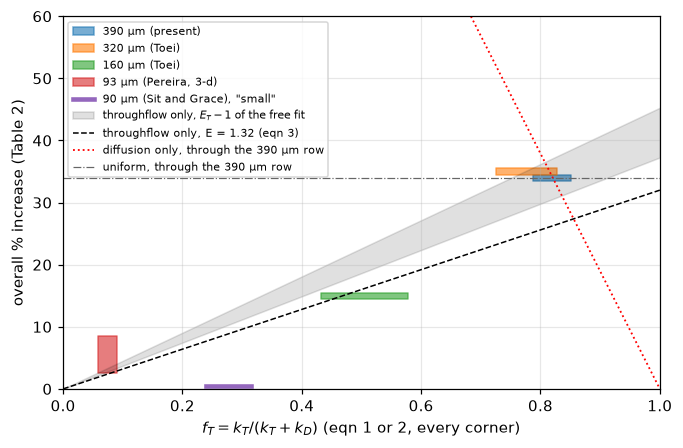

In [12]:
R0 = t2_rows(C0)
F0 = {k: fT_corners(C0, R0[k]) for k in ORDER}
fig, ax = plt.subplots(figsize=(7.0, 4.4))
lab = {"p390": "390 μm (present)", "t320": "320 μm (Toei)", "t160": "160 μm (Toei)", "per": "93 μm (Pereira, 3-d)",
       "sg90": "90 μm (Sit and Grace)"}
for k, col in zip(ORDER, ["C0", "C1", "C2", "C3", "C4"]):
    lo, hi = F0[k].min(), F0[k].max()
    if R0[k]["pct"] is None:
        ax.plot([lo, hi], [0.5, 0.5], color=col, lw=3, label=lab[k] + ', "small"')
        continue
    plo, phi_ = R0[k]["pct"]
    ax.fill_between([lo, hi], plo - 0.5, phi_ + 0.5, color=col, alpha=0.6, label=lab[k])
f = np.linspace(0, 1, 101)
ax.fill_between(f, 100 * M["r2_fit4_a_min"] * f, 100 * M["r2_fit4_a_max"] * f, color="k", alpha=0.12,
                label="throughflow only, $E_T - 1$ of the free fit")
ax.plot(f, 100 * 0.32 * f, "k--", lw=1, label="throughflow only, E = 1.32 (eqn 3)")
ax.plot(f, 34 * (1 - f) / (1 - F0["p390"].mean()), "r:", lw=1.2, label="diffusion only, through the 390 μm row")
ax.axhline(34, color="0.4", lw=0.8, ls="-.", label="uniform, through the 390 μm row")
ax.set(xlabel="$f_T = k_T/(k_T + k_D)$ (eqn 1 or 2, every corner)", ylabel="overall % increase (Table 2)",
       xlim=(0, 1), ylim=(0, 60))
ax.legend(fontsize=7, loc="upper left")
plt.show()

In [13]:
pairs0 = decidable_pairs(R0)
say("**(a) Ordering.** Table 2 decides <<np:d>> pairs (the 34 against 35 of the 390 and 320 μm rows is not decided: "
    "their $f_T$ intervals overlap, and the 90 μm \"small\" is ordered by the text only against the present work). Over all "
    "<<nj:d>> joint corners, throughflow-only enhancement orders <<ct>> of <<np:d>> as printed, diffusion-only "
    "<<cd>> of <<np:d>>, uniform <<cu:d>> of <<np:d>>; the smallest relative gap in $f_T$ within a decided pair is "
    "<<cm:pct0>>. The $f_T$ intervals of the 390 and 320 μm rows (<<f3>> and <<f2>>) <<ov>>, so their order "
    "cannot be tested.",
    np=M["r2_n_pairs"], nj=M["_n_joint"], ct=span(M["r2_conc_T_min"], M["r2_conc_T_max"], "d"),
    cd=span(M["r2_conc_D_min"], M["r2_conc_D_max"], "d"), cu=M["r2_conc_U"], cm=M["r2_conc__margin"],
    f3=M_span("r2_fT_p390", ".3f"), f2=M_span("r2_fT_t320", ".3f"),
    ov="overlap" if M["r2_overlap_390_320"] else "do not overlap")

**(a) Ordering.** Table 2 decides 6 pairs (the 34 against 35 of the 390 and 320 μm rows is not decided: their $f_T$ intervals overlap, and the 90 μm "small" is ordered by the text only against the present work). Over all 16384 joint corners, throughflow-only enhancement orders 6 of 6 as printed, diffusion-only 0 of 6, uniform 0 of 6; the smallest relative gap in $f_T$ within a decided pair is 25 %. The $f_T$ intervals of the 390 and 320 μm rows (0.788 to 0.851 and 0.725 to 0.828) overlap, so their order cannot be tested.

In [14]:
say("**(b) Size.** Read as throughflow-only, the rows imply $E_T - 1$ = <<a>> (390 μm), <<b>> (320 μm), <<c>> "
    "(160 μm) and <<d>> for Pereira's \"3-8\" (from <<e:.3f>> with the text's \"5-8%\"). Carried from the 390 μm "
    "row, the postulate predicts <<p>> % at 160 μm against the printed 15, above it and its half unit at <<n:d>> of "
    "<<N:d>> corners. Eqn (3)'s step E = 1.32 on the throughflow term predicts <<q1>> % (390 μm), <<q2>> % (320 μm), "
    "<<q3>> % (160 μm), <<q4>> % (Pereira) and <<q5>> % (90 μm); the printed constants 0.4 and 1/3 predict <<r1>>, "
    "<<r2>>, <<r3>>, <<r4>> and <<r5>> %. With their half units, <<i1:d>> of 4 printed values lie in the range E = "
    "1.32 predicts and <<i2:d>> of 4 in the range of the printed constants. These are different measures: the "
    "1.32 is meant for freely bubbling beds, Table 2's rows are pairs and streams.",
    a=M_span("r2_ET1_p390", ".3f"), b=M_span("r2_ET1_t320", ".3f"), c=M_span("r2_ET1_t160", ".3f"),
    d=M_span("r2_ET1_per", ".2f"), e=M["r2_ET1_per_text_min"], p=M_span("r2_pred160", ".1f"),
    n=M["r2_pred160_above"], N=M["_n_160"], **{f"q{i}": M_span(f"r2_pred132_{k}", ".1f") for i, k in enumerate(ORDER, 1)},
    **{f"r{i}": M_span(f"r2_predpc_{k}", ".1f") for i, k in enumerate(ORDER, 1)},
    i1=M["r2_inside_132"], i2=M["r2_inside_pc"])

**(b) Size.** Read as throughflow-only, the rows imply $E_T - 1$ = 0.400 to 0.432 (390 μm), 0.423 to 0.483 (320 μm), 0.259 to 0.347 (160 μm) and 0.33 to 1.38 for Pereira's "3-8" (from 0.557 with the text's "5-8%"). Carried from the 390 μm row, the postulate predicts 17.3 to 25.0 % at 160 μm against the printed 15, above it and its half unit at 64 of 64 corners. Eqn (3)'s step E = 1.32 on the throughflow term predicts 25.2 to 27.2 % (390 μm), 23.2 to 26.5 % (320 μm), 13.8 to 18.5 % (160 μm), 1.9 to 2.9 % (Pereira) and 7.7 to 10.1 % (90 μm); the printed constants 0.4 and 1/3 predict 20.2 to 21.8, 18.6 to 21.3, 11.1 to 14.8, 1.9 to 3.0 and 6.2 to 8.1 %. With their half units, 2 of 4 printed values lie in the range E = 1.32 predicts and 2 of 4 in the range of the printed constants. These are different measures: the 1.32 is meant for freely bubbling beds, Table 2's rows are pairs and streams.

In [15]:
say("**(c) Both parts free.** A least-squares fit of the increase to $(E_T - 1) f_T + (E_D - 1)(1 - f_T)$ on the "
    "four numeric rows (Pereira at 5.5, 3, 8 and the text's 6.5 %, two degrees of freedom, 95 % intervals from "
    "the t quantile) gives $E_T - 1$ = <<a>> and $E_D - 1$ = <<b>> over every corner, with half-widths <<h>>; "
    "$E_D$ = 1 lies inside the interval at <<n:d>> of <<N:d>> combinations of corner and Pereira value. The 160 μm "
    "row sits <<r>> points below the fit. Without Pereira's row (three rows, one degree of freedom) $E_T - 1$ = "
    "<<a3>>, $E_D - 1$ = <<b3>>, half-widths <<h3>>, and $E_D$ = 1 inside at <<n3:d>> of <<N3:d>> corners. "
    "With Pereira the fitted $E_D - 1$ <<s4>>; without it, it is <<s3>>. Four rows with two free parameters, "
    "measured in different ways, carry that much and no more. Where the three rows are nearly collinear the "
    "one-degree-of-freedom half-width falls to <<hmin:.3f>>, so the corners whose interval excludes 0 are no evidence "
    "of $E_D < 1$.",
    hmin=min(M["r2_fit3_bhw_min"], M["r2_fit4_bhw_min"]),
    s4=("brackets zero" if M["r2_fit4_b_min"] < 0 < M["r2_fit4_b_max"] else "keeps one sign"),
    s3=("negative at every corner" if M["r2_fit3_b_max"] < 0 else "of either sign"),
    a=M_span("r2_fit4_a", ".3f"), b=M_span("r2_fit4_b", ".3f"), h=M_span("r2_fit4_bhw", ".3f"),
    n=M["r2_fit4_b_ci0"], N=M["_n_fit4"], r=span(-M["r2_fit4_res160_max"], -M["r2_fit4_res160_min"], ".1f"), a3=M_span("r2_fit3_a", ".3f"),
    b3=M_span("r2_fit3_b", ".3f"), h3=M_span("r2_fit3_bhw", ".3f"), n3=M["r2_fit3_b_ci0"], N3=M["_n_fit3"])

**(c) Both parts free.** A least-squares fit of the increase to $(E_T - 1) f_T + (E_D - 1)(1 - f_T)$ on the four numeric rows (Pereira at 5.5, 3, 8 and the text's 6.5 %, two degrees of freedom, 95 % intervals from the t quantile) gives $E_T - 1$ = 0.373 to 0.453 and $E_D - 1$ = -0.033 to 0.040 over every corner, with half-widths 0.071 to 0.373; $E_D$ = 1 lies inside the interval at 16384 of 16384 combinations of corner and Pereira value. The 160 μm row sits 1.7 to 9.5 points below the fit. Without Pereira's row (three rows, one degree of freedom) $E_T - 1$ = 0.421 to 0.579, $E_D - 1$ = -0.416 to -0.051, half-widths 0.001 to 3.812, and $E_D$ = 1 inside at 472 of 512 corners. With Pereira the fitted $E_D - 1$ brackets zero; without it, it is negative at every corner. Four rows with two free parameters, measured in different ways, carry that much and no more. Where the three rows are nearly collinear the one-degree-of-freedom half-width falls to 0.001, so the corners whose interval excludes 0 are no evidence of $E_D < 1$.

### R3. The 390 μm coefficients against eqn (1)

The paper's conditions (p. 327, Table 2): $U_{mf}$ 11.2 cm/s, $\mathcal{D}_G$ 0.2 cm²/s,
$D_B$ 12 to 15 cm; $U_B$ from Fig. 4; $\epsilon_{mf}$ over its bracket. The 9.6, 8.5 and 3.4
cm/s are fits the paper does not print the data for; the page does only arithmetic on them.

In [16]:
say("Fig. 4 gives the front bubble's nose velocity in the approach period as <<ub:.1f>> ± <<se:.1f>> cm/s "
    "(slope and standard error of <<n:d>> markers). With it, eqn (1)'s throughflow term alone is <<kt:.4f>> times "
    "the isolated coefficient, whatever $\\epsilon_{mf}$ and $U_B$, and the whole of eqn (1) is <<K>> times it: eqn "
    "(1) cannot give the isolated value. It would at $U_{mf}$ = <<u>> cm/s. Fig. 4's slope corresponds to "
    "$c = U_B/(g D_B)^{1/2}$ = <<cf>> for the present work, <<cin>> the <<cb0>> to <<cb1>> bracket used for the Table 2 "
    "rows; the ordering count in R2 was evaluated on that bracket only.\n\n"
    "**The pair.** The printed coefficients are <<rv:.3f>> and <<ro:.3f>> times the isolated one, <<ni:d>> of 2 "
    "inside \"two to three times larger\". If only the throughflow term is enhanced, the approach-period "
    "multiplier is $E_T = (K_{pair} - k_D)/(K_{iso} - k_D)$ with the measured isolated base: <<bv>> (vertical) "
    "and <<bo>> (oblique); with eqn (1)'s own split, $(K_{pair} - k_D)/k_T$ = <<sv>> and <<so>>. Free of every "
    "unprinted input, $E_T \\ge K_{pair}/K_{iso}$ (the base case $k_D$ = 0), the two ratios above. The paper's 1.8 for "
    "the final 0.8 s is a different span (approach, encroachment and coalescence) and a fit not printed.\n\n"
    "**The verdict.** \"differ significantly at the 90% level of confidence, but not at the 95% level\" (p. 330), "
    "read as a two-sided normal test of the difference, implies a standard error of the difference between "
    "<<s95:.3f>> and <<s90:.3f>> cm/s (degrees of freedom not printed: an inversion, not a test).\n\n"
    "**Three numbers for one bed.** For 390 μm the paper prints 34 % (Table 2), \"only 64%\" for single bubbles "
    "(p. 330), which is <<e64:pct1>> more for the pair, and the 1.8 on the throughflow term, which is <<e18>> % on "
    "eqn (1)'s coefficient. They are not one quantity; the page does not rank them.",
    ub=M["r3_UB"], se=M["r3_UB_se"], n=fig4_slope(C0)[2], kt=M["r3_kT_over_iso"], K=M_span("r3_K1_over_iso", ".3f"),
    u=M_span("r3_umf_iso", ".2f"), cf=M_span("r3_c_fig4", ".2f"), cb0=C_BR[0], cb1=C_BR[1],
    cin=("inside" if C_BR[0] <= M["r3_c_fig4_min"] and M["r3_c_fig4_max"] <= C_BR[1] else "outside"), rv=M["r3_ratio_vert"], ro=M["r3_ratio_obl"], ni=M["r3_ratio_inside"],
    bv=M_span("r3_ET_base_vert", ".2f"), bo=M_span("r3_ET_base_obl", ".2f"), sv=M_span("r3_ET_split_vert", ".2f"),
    so=M_span("r3_ET_split_obl", ".2f"), s95=M["r3_se_95"], s90=M["r3_se_90"], e64=M["r3_enh_64"],
    e18=M_span("r3_enh_18", ".1f"))

Fig. 4 gives the front bubble's nose velocity in the approach period as 98.7 ± 1.0 cm/s (slope and standard error of 8 markers). With it, eqn (1)'s throughflow term alone is 1.0486 times the isolated coefficient, whatever $\epsilon_{mf}$ and $U_B$, and the whole of eqn (1) is 1.283 to 1.350 times it: eqn (1) cannot give the isolated value. It would at $U_{mf}$ = 7.47 to 8.17 cm/s. Fig. 4's slope corresponds to $c = U_B/(g D_B)^{1/2}$ = 0.81 to 0.91 for the present work, outside the 0.5 to 0.8 bracket used for the Table 2 rows; the ordering count in R2 was evaluated on that bracket only.

**The pair.** The printed coefficients are 2.824 and 2.500 times the isolated one, 2 of 2 inside "two to three times larger". If only the throughflow term is enhanced, the approach-period multiplier is $E_T = (K_{pair} - k_D)/(K_{iso} - k_D)$ with the measured isolated base: 3.38 to 3.61 (vertical) and 2.96 to 3.15 (oblique); with eqn (1)'s own split, $(K_{pair} - k_D)/k_T$ = 2.41 to 2.47 and 2.10 to 2.16. Free of every unprinted input, $E_T \ge K_{pair}/K_{iso}$ (the base case $k_D$ = 0), the two ratios above. The paper's 1.8 for the final 0.8 s is a different span (approach, encroachment and coalescence) and a fit not printed.

**The verdict.** "differ significantly at the 90% level of confidence, but not at the 95% level" (p. 330), read as a two-sided normal test of the difference, implies a standard error of the difference between 0.561 and 0.669 cm/s (degrees of freedom not printed: an inversion, not a test).

**Three numbers for one bed.** For 390 μm the paper prints 34 % (Table 2), "only 64%" for single bubbles (p. 330), which is 56.2 % more for the pair, and the 1.8 on the throughflow term, which is 62.2 to 65.4 % on eqn (1)'s coefficient. They are not one quantity; the page does not rank them.

### R4. Table 1 and the tracer balance

Each $V_B \times C_B$ is compared with the printed $V_BC_B$ in units of the allowance its
printed digits leave: half a unit of $V_B$ times $C_B$, $V_B$ times half a unit of $C_B$,
and half a unit of the product. The perimeter of the approach-period bubbles, which could
be traced from the contours of Figs. 2 and 3, is not measured here (an optional part of
the plan, dropped); the perimeter factor below is what Table 1 requires, not a measurement.

In [17]:
hu_names = [k for k in M if k.startswith("r4_hu_")]
print("V_B x C_B against the printed V_B C_B (allowances):")
for k in hu_names:
    print(f"  {k[6:]:<16} {M[k]:8.3f}")
say("<<n:d>> of <<N:d>> cells lie within their allowance (the 0.6 s front cell is exact). The 0.6 s rear cell is "
    "<<a:.1f>> allowances off and the 1.1 s cell <<b:.1f>>; the printed 1.74 is 620 × <<c:.4f>> %, <<cr:.2f>> times the "
    "printed 0.14. The printed sums and cumulative transfers follow the printed $V_BC_B$ column (<<s:d>> of 9), and "
    "<<p:d>> of 5 printed percentages (46, 77, 100 and 50 %, and the text's \"77% of the transfer occurring "
    "within the first 50%\") follow it within their half unit; the 38 % elapsed is <<e:pct1>> rounded up, exactly "
    "at the half unit. With 0.14 kept, the 77 % would be <<f:pct1>>. So the text and the sums agree with the "
    "printed 1.74 against the printed 0.14; at 0.6 s the rear cell would need $C_B$ = <<ci:.3f>> % or $V_B$ = "
    "<<vi:.0f>> cm³. The page does not decide which cell is right. The pair transfers <<tr:pct1>> of its tracer "
    "over the 0.8 s.",
    n=M["r4_cells_within"], N=M["_n_cells"], a=M["r4_hu_0.6_rear"], b=M["r4_hu_1.1_resultant"],
    c=M["r4_C_impl_11"], cr=M["r4_C_impl_11"] / float(cell(C0, "1.1", "resultant", "C_B_vol_pct")), s=M["r4_sums_ok"], p=M["r4_pct_within"], e=M["r4_elapsed06"], f=M["r4_frac07_if014"],
    ci=M["r4_C_impl_06r"], vi=M["r4_V_impl_06r"], tr=M["r4_transferred"])

V_B x C_B against the printed V_B C_B (allowances):
  0.3_front           0.388
  0.3_rear            0.476
  0.6_rear            6.508
  0.7_front           0.515
  0.7_rear            0.378
  1.1_resultant      23.760


5 of 7 cells lie within their allowance (the 0.6 s front cell is exact). The 0.6 s rear cell is 6.5 allowances off and the 1.1 s cell 23.8; the printed 1.74 is 620 × 0.2806 %, 2.00 times the printed 0.14. The printed sums and cumulative transfers follow the printed $V_BC_B$ column (9 of 9), and 5 of 5 printed percentages (46, 77, 100 and 50 %, and the text's "77% of the transfer occurring within the first 50%") follow it within their half unit; the 38 % elapsed is 37.5 % rounded up, exactly at the half unit. With 0.14 kept, the 77 % would be 60.5 %. So the text and the sums agree with the printed 1.74 against the printed 0.14; at 0.6 s the rear cell would need $C_B$ = 0.688 % or $V_B$ = 366 cm³. The page does not decide which cell is right. The pair transfers 64.5 % of its tracer over the 0.8 s.

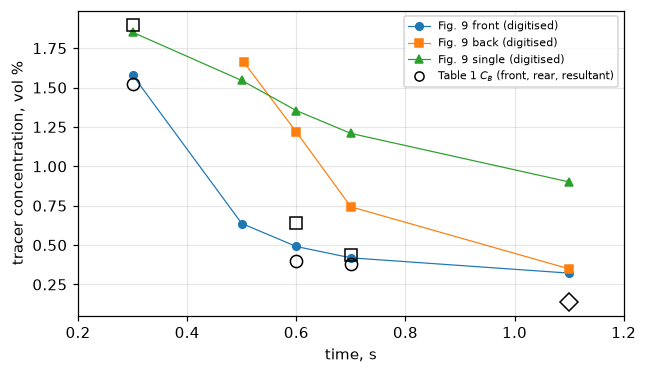

Table 1's concentrations are "averaged values taken from Fig. 9" (p. 330); the paper does not say how they were averaged. Read at the printed times the curves stand +0.059, +0.091, +0.039, +0.578, +0.303, +0.182 vol % above the table, and 0 of 6 lie within the reading error of 0.015 vol %. Table 1 prints its times to 0.1 s. By the secant slope of the digitised curve (the reads on either side of the cell, or its one neighbour at the end of the curve), a half unit of the printed time, 0.05 s, closes the gap for 1 of 6 table values, and the front bubble's curve falls 4.7 vol %/s at 0.3 s. The rear-bubble cells and the 1.1 s cell are not closed: the back curve stays 0.30 vol % or more above the rear cells, and its drawn part begins at about 0.5 s while Table 1 lists the rear bubble from 0.3 s. At 1.1 s the curves stand 0.041 (nearest curve) and 0.068 (back curve) vol % above the $C_B$ the printed product implies. A window average of the front curve over 0.5 to 0.7 s (trapezoid over its three reads) is 0.509 vol %, above the 0.6 s read of 0.491, so averaging does not close the gap to the table's 0.40. The page does not say whether the table or the figure is right.

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for cv, mk in (("front", "o"), ("back", "s"), ("single", "^")):
    d = f9[f9.curve == cv]
    ax.plot(d.time_s, d.C_vol_pct, mk + "-", ms=5, lw=0.8, label=f"Fig. 9 {cv} (digitised)")
T10 = t1_numbers(C0)
for (tm, bb), r in T10.items():
    ax.plot(float(tm), 100 * r["C"], {"front": "o", "rear": "s", "resultant": "D"}[bb], mfc="none", mec="k", ms=8)
ax.plot([], [], "o", mfc="none", mec="k", label="Table 1 $C_B$ (front, rear, resultant)")
ax.set(xlabel="time, s", ylabel="tracer concentration, vol %", xlim=(0.2, 1.2))
ax.legend(fontsize=7)
plt.show()
_imp11 = 100 * T10[("1.1", "resultant")]["P"] / T10[("1.1", "resultant")]["V"]
say("Table 1's concentrations are \"averaged values taken from Fig. 9\" (p. 330); the paper does not say how they were "
    "averaged. Read at the printed times the curves stand <<d>> vol % above the table, and <<n:d>> of <<N:d>> lie "
    "within the reading error of <<err:g>> vol %. Table 1 prints its times to 0.1 s. By the secant slope of the "
    "digitised curve (the reads on either side of the cell, or its one neighbour at the end of the curve), a "
    "half unit of the printed time, 0.05 s, closes the gap for <<nt:d>> of <<N:d>> table values, and the front "
    "bubble's curve falls <<s:.1f>> vol %/s at 0.3 s. The rear-bubble cells and the 1.1 s cell are not closed: the "
    "back curve stays <<gb:.2f>> vol % or more above the rear cells, and its drawn part begins at about 0.5 s while "
    "Table 1 lists the rear bubble from 0.3 s. At 1.1 s the curves stand <<i:.3f>> (nearest curve) and <<ib:.3f>> "
    "(back curve) vol % above the $C_B$ the printed product implies. A window average of the front curve over 0.5 to 0.7 s "
    "(trapezoid over its three reads) is <<w:.3f>> vol %, above the 0.6 s read of <<r:.3f>>, so averaging does not "
    "close the gap to the table's <<c:.2f>>. The page does not say whether the table or the figure is right.",
    d=", ".join(f"{M['r4_f9_' + k]:+.3f}" for k in ("0.3_front", "0.6_front", "0.7_front", "0.6_rear", "0.7_rear",
                                                     "1.1_resultant")),
    n=M["r4_f9_within"], N=M["_n_f9"], err=C0.f9_err, i=M["r4_f9_1.1_vs_implied"],
    nt=M["r4_f9_dt_within"], s=-M["r4_f9_slope_front_0.3"], gb=min(M["r4_f9_0.6_rear"], M["r4_f9_0.7_rear"]),
    ib=f9_read(C0, "back", 1.1) - _imp11, w=M["r4_f9_front_avg_06"], r=f9_read(C0, "front", 0.6),
    c=100 * T10[("0.6", "front")]["C"])

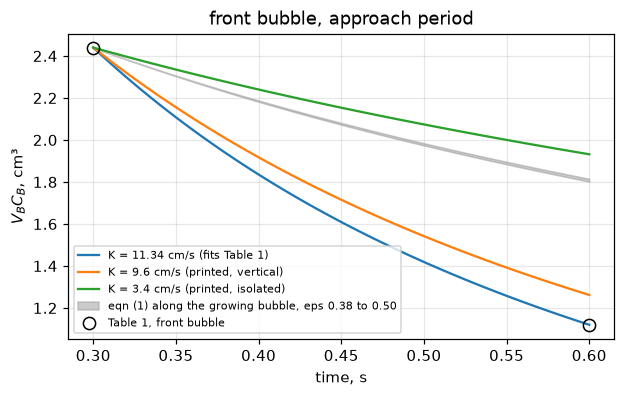

**The tracer balance (E9).** For the front bubble over the approach period (0.3 to 0.6 s, $V_B$ linear in time, $w$ = 0.9 cm), Table 1 implies $K$ = 11.34 cm/s (11.23 to 11.45 over half a unit of the printed volumes and products) at a perimeter factor 1; the printed 9.6 would follow at a transfer surface 1.181 times the circle's and the isolated 3.4 at 3.33 times, if Table 1's cells were the data behind them (they are fits to per-bubble data the paper does not print). With Table 1's volumes and the Fig. 9 front curve instead of the $C_B$ column, $K$ = 8.86 cm/s, and the printed 9.6 lies between the two. Marched forward from the 0.3 s cell, $V_BC_B$ at 0.6 s is 1.262 cm³ at $K$ = 9.6, 1.932 at 3.4 and 1.802 to 1.815 with eqn (1) along the growing bubble, against the printed 1.12. The rear bubble's apparent $K$ is 0.74 cm/s with the printed cell and 1.87 with the products; the page offers no mechanism for it.

In [19]:
t0_, t1x, V0_, V1_, y0_, y1_ = front_interval(C0)
tt = np.linspace(t0_, t1x, 61)
k_t0, _, t390 = r390(C0)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for K_, lab_ in ((M["r4_K_front"], f"K = {M['r4_K_front']:.2f} cm/s (fits Table 1)"),
                 (num(C0, "K_vertical_cm_s"), "K = 9.6 cm/s (printed, vertical)"),
                 (num(C0, "K_isolated_cm_s"), "K = 3.4 cm/s (printed, isolated)")):
    ax.plot(tt, [y0_ * math.exp(-K_ * int_s_over_v(t0_, x, V0_, V0_ + (V1_ - V0_) * (x - t0_) / (t1x - t0_), thickness(C0)))
                 if x > t0_ else y0_ for x in tt], label=lab_)
_UB, _w = fig4_slope(C0)[0], thickness(C0)
_V = lambda x: V0_ + (V1_ - V0_) * (x - t0_) / (t1x - t0_)
_band = [[y0_ * math.exp(-k_t0 * int_s_over_v(t0_, x, V0_, _V(x), _w)
                         - int_kd_s_over_v(t0_, x, V0_, _V(x), _w, t390["DG"], e_, _UB)) if x > t0_ else y0_
          for x in tt] for e_ in EPS_BR]
ax.fill_between(tt, *_band, color="0.6", alpha=0.5, label="eqn (1) along the growing bubble, eps 0.38 to 0.50")
ax.plot([t0_, t1x], [y0_, y1_], "ko", mfc="none", ms=8, label="Table 1, front bubble")
ax.set(xlabel="time, s", ylabel="$V_B C_B$, cm³", title="front bubble, approach period")
ax.legend(fontsize=7)
plt.show()
say("**The tracer balance (E9).** For the front bubble over the approach period (0.3 to 0.6 s, $V_B$ linear in "
    "time, $w$ = 0.9 cm), Table 1 implies $K$ = <<K:.2f>> cm/s (<<Kh>> over half a unit of the printed "
    "volumes and products) at a perimeter factor 1; the printed 9.6 would follow at a transfer surface <<p96:.3f>> "
    "times the circle's and the isolated 3.4 at <<p34:.2f>> times, if Table 1's cells were the data behind them (they "
    "are fits to per-bubble data the paper does not print). With Table 1's volumes and "
    "the Fig. 9 front curve instead of the $C_B$ column, $K$ = <<Kf:.2f>> cm/s, and the printed 9.6 lies <<btw>> the two. Marched forward from the 0.3 s "
    "cell, $V_BC_B$ at 0.6 s is <<v96:.3f>> cm³ at $K$ = 9.6, <<v34:.3f>> at 3.4 and <<v1>> with eqn (1) along the "
    "growing bubble, against the printed 1.12. The rear bubble's apparent $K$ is <<r1:.2f>> cm/s with the printed "
    "cell and <<r2:.2f>> with the products; the page offers no mechanism for it.",
    K=M["r4_K_front"], p96=M["r4_phi_96"], p34=M["r4_phi_34"], Kf=M["r4_K_fig9"], v96=M["r4_VC06_96"], Kh=M_span("r4_K_front_hu", ".2f"),
    btw=("between" if sorted([M["r4_K_fig9"], M["r4_K_front"]])[0] < num(C0, "K_vertical_cm_s") < max(M["r4_K_fig9"], M["r4_K_front"]) else "not between"),
    v34=M["r4_VC06_34"], v1=M_span("r4_VC06_eqn1", ".3f"), r1=M["r4_K_rear_printed"], r2=M["r4_K_rear_products"])

### R5. Eqns (3), (4) from the paper's numbers

"(Table 2)" for "the final 0.8 s" (p. 334) can only be Table 1, which spans 0.3 to 1.1 s
A printed constant is compared in half units of its last printed digit.

In [20]:
say("E5 gives E = <<E:.2f>>, as printed. Then $E/\\pi$ = <<ep:.4f>>, and the printed 0.4 is <<h3:.2f>> half units "
    "of its last digit away: the rounding to \"a single significant figure\" (p. 334) holds. $E/4$ = <<e4:.2f>>; "
    "$U_{mf}/3$ is <<to:.4f>> times it, and its denominator 3 is <<h4:.3f>> half units from $4/E$. Read back, 0.4 "
    "implies a coalescing fraction of <<f1:pct1>> and 1/3 of <<f2:pct1>>, against the 40 % used. Over the stated "
    "30 to 60 % the eqn (3) constant runs <<c3>> and the eqn (4) constant <<c4>>; <<n:d>> of 2 printed constants lie "
    "inside. At the 390 μm conditions eqn (3) gives <<k>> times eqn (1). The arithmetic from 1.8 and 40 % to the "
    "printed constants holds; the 1.8 itself and the 40 % are not tested by any number the paper prints.",
    E=M["r5_E"], ep=M["r5_E_over_pi"], h3=M["r5_hu_eqn3"], e4=M["r5_E_over_4"], to=M["r5_third_over"],
    h4=M["r5_hu_eqn4_den"], f1=M["r5_fc_04"], f2=M["r5_fc_13"], c3=span(M["r5_c3_lo"], M["r5_c3_hi"], ".3f"),
    c4=span(M["r5_c4_lo"], M["r5_c4_hi"], ".2f"), n=M["r5_inside"], k=M_span("r5_K3_over_K1", ".3f"))

E5 gives E = 1.32, as printed. Then $E/\pi$ = 0.4202, and the printed 0.4 is 0.40 half units of its last digit away: the rounding to "a single significant figure" (p. 334) holds. $E/4$ = 0.33; $U_{mf}/3$ is 1.0101 times it, and its denominator 3 is 0.061 half units from $4/E$. Read back, 0.4 implies a coalescing fraction of 32.1 % and 1/3 of 41.7 %, against the 40 % used. Over the stated 30 to 60 % the eqn (3) constant runs 0.395 to 0.471 and the eqn (4) constant 0.31 to 0.37; 2 of 2 printed constants lie inside. At the 390 μm conditions eqn (3) gives 1.199 to 1.210 times eqn (1). The arithmetic from 1.8 and 40 % to the printed constants holds; the 1.8 itself and the 40 % are not tested by any number the paper prints.

## Validation

### V1. The penetration problem (S4)

Space ladder in exact time (25 to 400 cells), against $2/\sqrt\pi$ for the absorbed amount
at $t$ = 1 and $1/\sqrt\pi$ for the face flux; then a backward Euler ladder on 800 cells.
Orders come from successive differences (`observed_orders`), never against the exact value.

In [21]:
print(pd.DataFrame({"cells": N_SPACE, "amount": M["_s4_amounts"],
                    "amount - 2/sqrt(pi)": np.array(M["_s4_amounts"]) - 2 / math.sqrt(math.pi)}).to_string(
    index=False, formatters={"amount": "{:.7f}".format, "amount - 2/sqrt(pi)": "{:.2e}".format}))
say("The amount converges at orders <<a>> and the face flux (read with `compute_boundary_values`) at <<f>>: fourth "
    "order, which is superconvergence of these two functionals on a uniform grid, not the order of the scheme (a "
    "second-order finite-volume operator). The Richardson estimates meet $2/\\sqrt{\\pi}$ and $1/\\sqrt{\\pi}$ "
    "to below 1e-10 (here <<ga:.1e>> and <<gf:.1e>>); the 100-cell amount is off by <<e:.3e>>. The cell amount equals "
    "the time-integrated face fluxes to below 1e-11 (discrete conservation, an identity; here <<i:.1e>>). Round-off "
    "companion: `expm_multiply` against the dense `expm` at 400 cells differs by less than 1e-2 of the finest "
    "ladder difference (here <<c:.1e>>). In time, backward Euler on 800 cells converges at orders <<b>> to an amount "
    "<<gb:.1e>> from $2/\\sqrt{\\pi}$ (bound 1e-6); `scipy.linalg.solve_banded` on the same tridiagonal system at the finest level differs by less than 1e-2 of "
    "the finest difference (here <<cb:.1e>>).",
    a=M_span("s4_amount_order", ".2f"), f=M_span("s4_flux_order", ".2f"), ga=M["s4_amount_gap"], gf=M["s4_flux_gap"],
    e=M["s4_amount_err_n100"], i=M["s4_identity"], c=M["s4_companion"], b=M_span("s4_be_order", ".3f"),
    gb=M["s4_be_gap"], cb=M["s4_be_companion"])

 cells    amount amount - 2/sqrt(pi)
    25 1.1280361           -3.43e-04
    50 1.1283574           -2.18e-05
   100 1.1283778           -1.37e-06
   200 1.1283791           -8.56e-08
   400 1.1283792           -5.35e-09


The amount converges at orders 3.98 to 4.00 and the face flux (read with `compute_boundary_values`) at 3.96 to 4.00: fourth order, which is superconvergence of these two functionals on a uniform grid, not the order of the scheme (a second-order finite-volume operator). The Richardson estimates meet $2/\sqrt{\pi}$ and $1/\sqrt{\pi}$ to below 1e-10 (here 6.1e-12 and 1.5e-11); the 100-cell amount is off by -1.369e-06. The cell amount equals the time-integrated face fluxes to below 1e-11 (discrete conservation, an identity; here 1.4e-13). Round-off companion: `expm_multiply` against the dense `expm` at 400 cells differs by less than 1e-2 of the finest ladder difference (here 5.6e-07). In time, backward Euler on 800 cells converges at orders 0.999 to 1.000 to an amount 5.5e-08 from $2/\sqrt{\pi}$ (bound 1e-6); `scipy.linalg.solve_banded` on the same tridiagonal system at the finest level differs by less than 1e-2 of the finest difference (here 1.7e-10).

### V2. The tracer march (S1)

Backward Euler with $\Delta t$ = 0.3/(20·2^k) s, k = 0 to 5; at each level `find_roots` gives
the $K$ for which the march reproduces the printed 1.12 at 0.6 s. The same ladder for
$V_BC_B$(0.6 s) with eqn (1) along the growing bubble at the test condition T.

In [22]:
say("$K$ converges at orders <<a>> and its Richardson estimate meets the closed form <<Kc:.7f>> cm/s to <<g:.1e>> "
    "relative (bound 1e-4); $V_BC_B$ with eqn (1) at orders <<b>>, to <<gv:.1e>> of <<Vc:.6f>> cm³. Round-off "
    "companion: the finest $K$ by a sum of logarithms instead of a product differs by less than 1e-2 of the "
    "finest difference (here <<c:.1e>>).",
    a=M_span("s1_K_order", ".3f"), Kc=M["_s1_Kc"], g=M["s1_K_gap"], b=M_span("s1_VC_order", ".3f"), gv=M["s1_VC_gap"],
    Vc=M["_s1_VCc"], c=M["s1_companion"])

$K$ converges at orders 1.002 to 1.016 and its Richardson estimate meets the closed form 11.3386565 cm/s to 1.5e-06 relative (bound 1e-4); $V_BC_B$ with eqn (1) at orders 0.985 to 0.998, to 2.5e-07 of 1.817221 cm³. Round-off companion: the finest $K$ by a sum of logarithms instead of a product differs by less than 1e-2 of the finest difference (here 7.9e-12).

### V3. Closed forms and V4. Check values

The renewal quadrature returns the sphere factor 1 (R1), which validates the code that
gives the circle's 0.9003; eqns (1) to (4) at T and every Table 2 statement at T2 are rows of
the check values; every Table 2 statement on this page holds over every corner of its
brackets (R2). All 100 check values from the second route were reproduced before the first
number was registered.

In [23]:
print(f"check values: {len(CHECK_DEV)} rows, worst relative deviation {max(abs(v) for v in CHECK_DEV.values()):.1e}")

check values: 100 rows, worst relative deviation 4.4e-12


## Finding

In [24]:
say("The paper calls its explanation \"semi-quantitative\" (p. 333), and its numbers allow no more than that.\n\n"
    "- **Table 2 <<hd>>.** Throughflow-only enhancement orders <<ct>> of <<np:d>> decidable "
    "pairs as printed at every corner, diffusion-only <<cd>>, uniform <<cu:d>>. The 34 against 35 cannot be tested "
    "(overlapping $f_T$).\n"
    "- **The size is not one number.** The implied $E_T - 1$ is <<a>> at 390 μm and <<b>> at 160 μm; carried from "
    "390 μm the postulate overpredicts the 160 μm row (<<p>> % against 15). Both parts free, with Pereira, $E_D - 1$ = "
    "<<fb>> and its interval contains 0 at <<n4:d>> of <<N4:d>> combinations; without Pereira $E_D - 1$ = <<fb3>>, "
    "0 inside at <<n3:d>> of <<N3:d>>. The table is consistent with the postulate and does not prove it.\n"
    "- **The 390 μm coefficients do not fit eqn (1).** $U_{mf}/\\pi$ alone is <<kt:.4f>> times the isolated 3.4 cm/s, "
    "and <<kh:.3f>> times it with both printed values moved half a unit against the gap, so eqn (1), at <<K>> times it "
    "for the whole coefficient, cannot give it. The paper prints no error for the 3.4 cm/s, and the page does not say "
    "whether eqn (1), the 11.2 or the 3.4 is off. With the measured isolated base, the throughflow multiplier of the approach period is at "
    "least <<lv:.2f>> (vertical) and <<lo:.2f>> (oblique); with eqn (1)'s own throughflow term it is <<sv>> and <<so>>. "
    "All are <<cmp>> the 1.8 that eqns (3), (4) use for a different span.\n"
    "- **Table 1** implies $K$ = <<Kf:.2f>> cm/s for the front bubble (<<Kh>> over half a unit of the printed volumes "
    "and products), and <<K9:.2f>> with the Fig. 9 front curve and the same volumes; the printed 9.6 lies <<btw>> the "
    "two, so the tracer accounting does not test it. Two of its cells are off their products by <<h1:.1f>> and "
    "<<h2:.1f>> allowances.\n"
    "- **Eqns (3), (4)** follow from 1.8 and 40 % <<w>> half a unit of their printed digit (<<h3:.2f>> and "
    "<<h4:.3f>> half units); over the stated 30 to 60 %, <<ni:d>> of 2 printed constants stay inside the range. The 1.8 and the "
    "40 % themselves are not supported or tested by any printed number, and nothing here tests eqns (3), (4) "
    "against a freely bubbling bed.",
    ct=span(M["r2_conc_T_min"], M["r2_conc_T_max"], "d"), np=M["r2_n_pairs"],
    cd=span(M["r2_conc_D_min"], M["r2_conc_D_max"], "d"), cu=M["r2_conc_U"], a=M_span("r2_ET1_p390", ".2f"),
    b=M_span("r2_ET1_t160", ".2f"), p=M_span("r2_pred160", ".1f"), fb=M_span("r2_fit4_b", ".3f"),
    n4=M["r2_fit4_b_ci0"], N4=M["_n_fit4"], fb3=M_span("r2_fit3_b", ".3f"), n3=M["r2_fit3_b_ci0"], N3=M["_n_fit3"],
    kt=M["r3_kT_over_iso"], kh=M["r3_kT_over_iso_hu_min"], K=M_span("r3_K1_over_iso", ".2f"), lv=M["r3_ratio_vert"], lo=M["r3_ratio_obl"],
    Kf=M["r4_K_front"], Kh=M_span("r4_K_front_hu", ".2f"), K9=M["r4_K_fig9"],
    btw=("between" if min(M["r4_K_fig9"], M["r4_K_front"]) < num(C0, "K_vertical_cm_s") < max(M["r4_K_fig9"], M["r4_K_front"]) else "not between"), h1=M["r4_hu_0.6_rear"], h2=M["r4_hu_1.1_resultant"],
    h3=M["r5_hu_eqn3"], h4=M["r5_hu_eqn4_den"], ni=M["r5_inside"],
    hd=("orders as the postulate says" if M["r2_conc_T_min"] == M["r2_n_pairs"] else "does not order as the postulate says"),
    sv=M_span("r3_ET_split_vert", ".2f"), so=M_span("r3_ET_split_obl", ".2f"),
    cmp=("above" if min(M["r3_ratio_vert"], M["r3_ratio_obl"], M["r3_ET_split_vert_min"], M["r3_ET_split_obl_min"]) > num(C0, "enh_throughflow") else "not above"),
    w=("within" if max(M["r5_hu_eqn3"], M["r5_hu_eqn4_den"]) < 1 else "not within"))

The paper calls its explanation "semi-quantitative" (p. 333), and its numbers allow no more than that.

- **Table 2 orders as the postulate says.** Throughflow-only enhancement orders 6 of 6 decidable pairs as printed at every corner, diffusion-only 0, uniform 0. The 34 against 35 cannot be tested (overlapping $f_T$).
- **The size is not one number.** The implied $E_T - 1$ is 0.40 to 0.43 at 390 μm and 0.26 to 0.35 at 160 μm; carried from 390 μm the postulate overpredicts the 160 μm row (17.3 to 25.0 % against 15). Both parts free, with Pereira, $E_D - 1$ = -0.033 to 0.040 and its interval contains 0 at 16384 of 16384 combinations; without Pereira $E_D - 1$ = -0.416 to -0.051, 0 inside at 472 of 512. The table is consistent with the postulate and does not prove it.
- **The 390 μm coefficients do not fit eqn (1).** $U_{mf}/\pi$ alone is 1.0486 times the isolated 3.4 cm/s, and 1.029 times it with both printed values moved half a unit against the gap, so eqn (1), at 1.28 to 1.35 times it for the whole coefficient, cannot give it. The paper prints no error for the 3.4 cm/s, and the page does not say whether eqn (1), the 11.2 or the 3.4 is off. With the measured isolated base, the throughflow multiplier of the approach period is at least 2.82 (vertical) and 2.50 (oblique); with eqn (1)'s own throughflow term it is 2.41 to 2.47 and 2.10 to 2.16. All are above the 1.8 that eqns (3), (4) use for a different span.
- **Table 1** implies $K$ = 11.34 cm/s for the front bubble (11.23 to 11.45 over half a unit of the printed volumes and products), and 8.86 with the Fig. 9 front curve and the same volumes; the printed 9.6 lies between the two, so the tracer accounting does not test it. Two of its cells are off their products by 6.5 and 23.8 allowances.
- **Eqns (3), (4)** follow from 1.8 and 40 % within half a unit of their printed digit (0.40 and 0.061 half units); over the stated 30 to 60 %, 2 of 2 printed constants stay inside the range. The 1.8 and the 40 % themselves are not supported or tested by any printed number, and nothing here tests eqns (3), (4) against a freely bubbling bed.

## What pymrm adds

One small solve and the checks, not the model. Every quantity on this page also has a
closed form (the Higbie integral for the penetration term, power-law integrals in $V_B$
for the tracer balance), and those closed forms are the second route and the check values:
pymrm adds verification, not a result the closed forms cannot give.

The penetration solve (`construct_grad` with Dirichlet dictionaries, `construct_div`,
`compute_boundary_values` for the face flux) is the numerical derivation of the one part
of eqn (1) the paper takes from a theory it does not print, the $4/\pi$ and the square root
of the diffusive term; it mirrors page `E1.2`, which solves the throughflow. The implicit
march of the tracer balance of a growing bubble is plain numpy, and `pymrm.checks.find_roots`
inverts it for $K$. `pymrm.checks.observed_orders` measures every ladder, including the
fourth-order superconvergence of the penetration functionals.

## Reuse

- To evaluate eqns (1) to (4) for another bed, call `k_throughflow` and `k_diffusion` from
  `model.py`; $\epsilon_{mf}$ and $U_B$ must come from the user, the paper prints neither.
  Read eqn (3) as the paper does: a constant to one significant figure resting on one pair
  and a visual estimate, not a fit to a freely bubbling bed.
- The throughflow term is Murray's, half of Davidson's in 2-D and a third in 3-D (page
  `E1.2`). A reactor model that uses Davidson's throughflow (page `E2.1`) and adds an
  enhancement from this paper applies it to a different base.
- `Penetration` is a template for any Higbie-type exposure problem with a Dirichlet face
  read through `compute_boundary_values`; `tracer_march` for any first-order exchange of a
  volume that grows in time.
- Related pages: `E1.2` (throughflow and cloud), `E1.1` (two-phase theory), `E2.1`
  (Kunii-Levenspiel bubbling bed), `E1.3` (bubble growth).

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through a field of the configuration (a reading of the model, a pymrm solver
setting, a mistyped printed number or a changed data point) and reruns the whole study;
a row whose study raises records nan for every claim, and a row that ran records its finite values. The
controls fail nothing.

In [25]:
def printed(name, new):
    """A mistyped printed number."""
    return f"printed {name} {C0.pn[name]} read {new}", replace(C0, pn={**C0.pn, name: new})


def t1_cell(time, bubble, col, new):
    d = C0.t1.copy()
    i = d.index[(d.time_s == time) & (d.bubble == bubble)][0]
    old, d.loc[i, col] = d.loc[i, col], new
    return f"Table 1 {time} s {bubble} {col} {old} read {new}", replace(C0, t1=d)


def t2_cell(dp, col, new):
    d = C0.t2.copy()
    i = d.index[d.dp_um == dp][0]
    old, d.loc[i, col] = d.loc[i, col], new
    return f"Table 2 {dp} um {col} {old} read {new}", replace(C0, t2=d)


def f9_swap():
    d = C0.f9.copy()
    m = d.time_s.isin([0.6, 0.7]) & d.curve.isin(["front", "back"])
    d.loc[m, "curve"] = d.loc[m, "curve"].map({"front": "back", "back": "front"})
    return "Fig. 9 front and back curves swapped at 0.6 and 0.7 s (nearest-pixel assignment)", replace(C0, f9=d)


def f9_scale(f):
    d = C0.f9.copy()
    d["C_vol_pct"] = d.C_vol_pct * f
    return f"Fig. 9 concentration axis x {f:g}", replace(C0, f9=d)


def f4_marker(i, dh):
    d = C0.f4.copy()
    d.loc[i, "height_cm"] = d.loc[i, "height_cm"] + dh
    return f"Fig. 4 marker at {d.time_s[i]:.2f} s read {dh:+g} cm", replace(C0, f4=d)


SWAP_M = {"murray": THROUGHFLOW["davidson"], "davidson": THROUGHFLOW["davidson"]}
SWAP_D = {"murray": THROUGHFLOW["murray"], "davidson": THROUGHFLOW["murray"]}
DEFECTS = [
    ("Davidson throughflow in place of Murray's (2 U_mf/pi, 3 U_mf/4)", replace(C0, table=SWAP_M)),
    ("Murray's q in place of Davidson's in the E1.2 comparison", replace(C0, table=SWAP_D)),
    ("eps_mf outside the root (effective diffusivity eps D_G)", replace(C0, convention="effective")),
    ("bubble radius in place of D_B in the penetration term", replace(C0, size_factor=0.5)),
    ("enhancement on the whole coefficient", replace(C0, enhance_on="whole")),
    ("enhancement on the diffusive term", replace(C0, enhance_on="diffusion")),
    ("eqn (2) for the 2-d rows", replace(C0, dim_2d=3)),
    ("eqn (1) for Pereira's 3-d row", replace(C0, dim_3d=2)),
    ("bubble thickness 9 cm for 9 mm", replace(C0, w_cm=9.0)),
    ("C_B = 0.14 kept at 1.1 s (V_B x C_B for the printed V_B C_B)", replace(C0, c11="product")),
    ("V_B held at its 0.3 s value in E9", replace(C0, hold_volume=True)),
    ("complement f_c for 1 - f_c in E5", replace(C0, complement="fc")),
    ("far boundary of the penetration problem at L = 2", replace(C0, L=2.0)),
    ("mis-signed Dirichlet dictionary at x = 0 (d = -1)", replace(C0, d_left=-1.0)),
    ("first cell starts at the boundary value", replace(C0, first_cell=1.0)),
    ("trapezoidal weight 0.5 in both time ladders", replace(C0, theta=0.5)),
    ("march of C_B, not V_B C_B (growth dilution dropped)", replace(C0, dilution=False)),
    ("S4 round-off companions with the boundary value 1e-4 high", replace(C0, comp_scale=1 + 1e-4)),
    ("S1 round-off companion with V_B C_B(0.3 s) 1e-4 high", replace(C0, comp_s1=1 + 1e-4)),
    ("circle surface velocity 1.5 U (the sphere's)", replace(C0, renewal_circle=1.5)),
    ("sphere surface velocity 2 U (the circle's)", replace(C0, renewal_sphere=2.0)),
    ("one-sided normal quantiles for the 90 %/95 % verdict", replace(C0, quantile="one-sided")),
    ("normal quantile for the t quantile in the free fit", replace(C0, fit_q="normal")),
    ("Table 1 allowance without the product's half unit", replace(C0, hu_product=False)),
    ("Fig. 9 reading error 0.15 for 0.015 vol %", replace(C0, f9_err=0.15)),
    printed("K_vertical_cm_s", "10.6"), printed("K_isolated_cm_s", "4.3"),
    printed("single_total_over_pair_pct", "46"), printed("enh_throughflow", "1.6"),
    printed("eqn3_const", "0.5"), printed("pereira_text_pct", "6-8"),
    t1_cell("0.6", "rear", "VBCB_cm3", "2.43"), t1_cell("0.6", "rear", "V_B_cm3", "366"),
    t1_cell("1.1", "resultant", "VBCB_cm3", "1.47"), t1_cell("1.1", "resultant", "C_B_vol_pct", "0.41"),
    t1_cell("0.6", "front", "VBCB_cm3", "1.21"), t1_cell("0.3", "rear", "C_B_vol_pct", "1.09"),
    t1_cell("0.7", "front", "C_B_vol_pct", "0.83"),
    ("Table 1 last time 1.1 read 1.0", replace(C0, t1=C0.t1.assign(time_s=C0.t1.time_s.replace("1.1", "1.0")))),
    t2_cell("160", "overall_pct_inc", "34"), t2_cell("320", "umf_cm_s", "2.8"), t2_cell("390", "umf_cm_s", "1.12"),
    t2_cell("93", "overall_pct_inc", "13-18"), t2_cell("390", "DB_cm", "12"), t2_cell("160", "overall_pct_inc", "21"),
    f9_swap(), f9_scale(0.98), f4_marker(7, 2.0),
]
CONTROLS = [("control: clean rerun", C0),
            ("control: Table 2 rows in reverse order", replace(C0, t2=C0.t2.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()
for row, c_ in CONTROLS + DEFECTS:
    try:
        with np.errstate(divide="ignore", invalid="ignore"):
            Mb = study(c_)
    except (ValueError, RuntimeError, ZeroDivisionError, KeyError, IndexError) as e:
        print(f"{row}: {type(e).__name__}: {e}")
        Mb = {name: float("nan") for name in claims.metrics}      # a study that raises records nan
        CRASH.add(row)
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if row not in CRASH and (x_ is None or (isinstance(x_, (float, np.floating)) and not np.isfinite(x_))):
            continue                  # a row that ran records only its finite values
        BREAK.append((row, name, claims.breaks(row, name, x_)))

In [26]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<66} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:66]:<66} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                                    claims failed
control: clean rerun                                                           0
control: Table 2 rows in reverse order                                         0
Davidson throughflow in place of Murray's (2 U_mf/pi, 3 U_mf/4)               75
Murray's q in place of Davidson's in the E1.2 comparison                       3
eps_mf outside the root (effective diffusivity eps D_G)                       79
bubble radius in place of D_B in the penetration term                         79
enhancement on the whole coefficient                                          43
enhancement on the diffusive term                                             43
eqn (2) for the 2-d rows                                                      63
eqn (1) for Pereira's 3-d row                                                 17
bubble thickness 9 cm for 9 mm                                                12
C_B = 0.14 kept at 1.1 s (V_

In [27]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for E1.4:
  r1_dims_ok            = 10               exact  exact
  r4_sums_ok            = 9                exact  exact
  r1_md_2d              = 0.5              value  rtol 1e-06
  r1_md_3d              = 0.33333          value  rtol 1e-06
  r1_E12_gap            = (here 4.4e-07)   bound  bound <= 1e-05 [theory]
  r1_renewal_circle     = 0.90032          value  rtol 1e-06
  r1_renewal_sphere_gap = (here 0.0e+00)   bound  bound <= 1e-10 [tolerance]
  r1_m8_min             = 0.07955          value  rtol 1e-06
  r1_m8_max             = 0.10202          value  rtol 1e-06
  r1_m9_min             = 0.61644          value  rtol 1e-06
  r1_m9_max             = 0.70711          value  rtol 1e-06
  s4_amount_order_min   = (here 4.0e+00)   bound  bound [3.9, 4.1] [theory]
  s4_amount_order_max   = (here 4.0e+00)   bound  bound [3.9, 4.1] [theory]
  s4_flux_order_min     = (here 4.0e+00)   bound  bound [3.9, 4.1] [theory]
  s4_flux_order_max     = (here 4.0e+00)   bound  bound [3.9, 4.1